In [ ]:
!pip install pymatgen matminer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 1.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.1/829.1 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━

In [ ]:
!pip install mp-api

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.2/114.2 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.5/140.5 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 79.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.1/126.1 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.6/88.6 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 388.0/388.0 kB 27.7 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfull

In [ ]:
import os, sys
from google.colab import drive

# 1. Mount your Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matminer.featurizers.composition import ElementProperty
from matminer.featurizers.base import MultipleFeaturizer
from matminer.utils.data import MagpieData
from pymatgen.core import Composition
from sklearn.model_selection import GroupShuffleSplit, cross_val_score
from pymatgen.symmetry.groups import SpaceGroup
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
#from catboost import CatBoostRegressor
#import optuna
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

In [ ]:
from mp_api.client import MPRester
import pandas as pd

API_KEY = "" #Materials Project API key

transition_metals = ["Fe","Co","Ni","Mn","Ti","V","Cr"]

os.makedirs("/content/drive/MyDrive/Battery Research/battery_materials_cifs", exist_ok=True)
fields = [
    "material_id",
    "formula_pretty",
    "band_gap",
    "formation_energy_per_atom",
    "energy_above_hull",
    "density",
    "volume",
    "nsites",
    "elements",
    "symmetry",
    "structure"
]

all_materials = []
with MPRester(API_KEY) as mpr:
  for tm in transition_metals:
    print(f"Retrieving Li-{tm}-O materials...")
    docs = mpr.materials.summary.search(
        # Must contain these elements
        elements = ["Li",tm,"O"],
        # Stable materials only
        energy_above_hull = (0,0.05),
        # Reasonable compound complexity
        num_elements = (3,6),
        # Required properties
        fields = fields
    )
    for doc in docs:
      #Save material structure as cif file
      if doc.structure:
        doc.structure.to(filename=f"/content/drive/MyDrive/Battery Research/battery_materials_cifs/{doc.material_id}.cif")
      material_data = {
          "material_id": str(doc.material_id),
          "formula": doc.formula_pretty,
          "band_gap": doc.band_gap,
          "formation_energy": doc.formation_energy_per_atom,
          "energy_above_hull": doc.energy_above_hull,
          "density": doc.density,
          "volume": doc.volume,
          "nsites": doc.nsites,
          "crystal_system": (
              doc.symmetry.crystal_system
              if doc.symmetry else None
          ),
          "space_group": (
              doc.symmetry.symbol
              if doc.symmetry else None
          ),
          "space_group_number": (
              doc.symmetry.number
              if doc.symmetry else None
          ),
          "elements": [str(e) for e in doc.elements]
      }

      all_materials.append(material_data)


# Create the dataframe
df = pd.DataFrame(all_materials)
# Remove duplicates
df = df.drop_duplicates(subset="material_id")
# Remove rows with missing targets
df = df.dropna(subset=["band_gap", "formation_energy"])
# Save the dataset as .pkl and .csv
#df.to_pickle("Battery Materials.pkl")
df.to_csv("battery_materials.csv", index=False)
df[['material_id', 'formula','band_gap']].to_csv("/content/drive/MyDrive/Battery Research/battery_materials_cifs/battery_prop.csv",index=False,header=False)   # No header — CGCNN expects plain id,value row

Retrieving Li-Fe-O materials...


Retrieving SummaryDoc documents:   0%|          | 0/1177 [00:00<?, ?it/s]

Retrieving Li-Co-O materials...


Retrieving SummaryDoc documents:   0%|          | 0/651 [00:00<?, ?it/s]

Retrieving Li-Ni-O materials...


Retrieving SummaryDoc documents:   0%|          | 0/584 [00:00<?, ?it/s]

... (4 outputs left out)

Retrieving Li-V-O materials...


Retrieving SummaryDoc documents:   0%|          | 0/1299 [00:00<?, ?it/s]

Retrieving Li-Cr-O materials...


Retrieving SummaryDoc documents:   0%|          | 0/723 [00:00<?, ?it/s]

In [ ]:
pip install optuna catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.3 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostRegressor
import optuna

In [ ]:
def visualize_feature_importance(model, feature_names, top_n=None, color=None):

    # Extract feature importances
    importance = model.feature_importances_

    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance
    }).sort_values(by='Importance', ascending=False)

    top_features = importance_df.head(top_n)

    if color is None:
      color = 'skyblue'

    # Plot feature importances

    plt.figure(figsize=(10, 6))
    plt.barh(top_features['Feature'], top_features['Importance'], color=color)
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.title(f'Top {top_n} Features')
    plt.gca().invert_yaxis()  # Invert y-axis to show the most important at the top
    plt.show()

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Battery Research/battery_materials.csv")
df.head()

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,space_group_number,elements
0,mp-780192,Li5FeO4,2.6187,-1.994978,0.047048,2.505206,409.758452,40,Triclinic,P1,1,"['Fe', 'Li', 'O']"
1,mp-1177943,Li2FeO2,3.1408,-1.836257,0.043743,3.630131,186.130640,20,Monoclinic,C2/m,12,"['Fe', 'Li', 'O']"
2,mp-887724,Li2FeO3,1.0267,-1.874446,0.003513,3.856510,202.760828,24,Monoclinic,C2/m,12,"['Fe', 'Li', 'O']"
3,mp-756155,Li6FeO4,2.7019,-1.961743,0.025520,2.566594,417.920661,44,Tetragonal,P4_2/nmc,137,"['Fe', 'Li', 'O']"
4,mp-1272755,Li2FeO2,3.0406,-1.835668,0.044332,3.660974,184.562545,20,Monoclinic,P2_1/c,14,"['Fe', 'Li', 'O']"


In [ ]:
df.tail(15)

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,space_group_number,elements
5154,mp-1101527,LiCr4P7O24,2.1691,-2.594289,0.034258,3.030534,893.932976,72,Triclinic,P-1,2,"['Cr', 'Li', 'O', 'P']"
5155,mp-26913,LiCr4(PO4)3,2.6503,-2.470605,0.028051,3.192684,519.940619,40,Triclinic,P-1,2,"['Cr', 'Li', 'O', 'P']"
5156,mp-705154,LiCr4P7O24,2.1798,-2.586079,0.042468,3.062891,884.489348,72,Triclinic,P-1,2,"['Cr', 'Li', 'O', 'P']"
5157,mp-26967,LiCr4(PO4)3,2.6429,-2.498656,0.000000,3.477258,954.778859,80,Orthorhombic,Pnma,62,"['Cr', 'Li', 'O', 'P']"
5158,mp-1176987,Li9Cr4P4(CO7)4,0.3860,-2.412655,0.035679,2.699053,547.785400,49,Triclinic,P1,1,"['C', 'Cr', 'Li', 'O', 'P']"
5159,mp-757087,Li7Cr5O12,0.0000,-2.298039,0.034429,3.847665,216.027127,24,Monoclinic,C2/m,12,"['Cr', 'Li', 'O']"
5160,mp-753172,Li4Cr5O10,0.0000,-2.326938,0.034968,4.020966,369.805287,38,Triclinic,P-1,2,"['Cr', 'Li', 'O']"
5161,mp-1101544,Li2Cr5(PO4)4,2.5834,-2.499005,0.018508,3.223069,336.813785,27,Triclinic,P-1,2,"['Cr', 'Li', 'O', 'P']"
5162,mp-697796,Li2Cr5(PO4)4,2.3591,-2.479060,0.038452,3.247632,334.266321,27,Triclinic,P-1,2,"['Cr', 'Li', 'O', 'P']"
5163,mp-867580,Li2Cr5(Si2O7)2,2.6538,-2.660145,0.000000,3.380536,599.463769,50,Triclinic,P-1,2,"['Cr', 'Li', 'O', 'Si']"


In [ ]:
import ast
unique_elements = df["elements"].explode().unique()

# 1. Create a set to collect unique individual elements
chemical_elements = set()

# 2. Loop through the array, parse the string, and extract elements
for string_representation in unique_elements:
    # Convert the string "['Fe', 'Li', 'O']" into a real Python list
    actual_list = ast.literal_eval(string_representation)

    # Add each individual chemical element to the set
    for element in actual_list:
        chemical_elements.add(element)

# 3. Convert the set back to a sorted list
final_list = sorted(list(chemical_elements))
print(final_list)


['Ac', 'Ag', 'Al', 'As', 'B', 'Ba', 'Bi', 'C', 'Ca', 'Cl', 'Co', 'Cr', 'Cs', 'Cu', 'F', 'Fe', 'Ga', 'Ge', 'H', 'I', 'In', 'Ir', 'K', 'La', 'Li', 'Mg', 'Mn', 'Mo', 'N', 'Na', 'Nb', 'Nd', 'Ni', 'O', 'P', 'Pb', 'Pd', 'Pr', 'Pt', 'Rb', 'Rh', 'Ru', 'S', 'Sb', 'Sc', 'Se', 'Si', 'Sm', 'Sn', 'Sr', 'Ta', 'Tb', 'Tc', 'Te', 'Ti', 'U', 'V', 'W', 'Y', 'Zn', 'Zr']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5169 entries, 0 to 5168
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   material_id         5169 non-null   object 
 1   formula             5169 non-null   object 
 2   band_gap            5169 non-null   float64
 3   formation_energy    5169 non-null   float64
 4   energy_above_hull   5169 non-null   float64
 5   density             5169 non-null   float64
 6   volume              5169 non-null   float64
 7   nsites              5169 non-null   int64  
 8   crystal_system      5169 non-null   object 
 9   space_group         5169 non-null   object 
 10  space_group_number  5169 non-null   int64  
 11  elements            5169 non-null   object 
dtypes: float64(5), int64(2), object(5)
memory usage: 484.7+ KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
band_gap,5169.0,1.468972,1.243224,0.000000,0.358000,1.187600,2.445400,5.304000
formation_energy,5169.0,-2.346397,0.402686,-3.649436,-2.613704,-2.418412,-2.113507,-0.602868
energy_above_hull,5169.0,0.026266,0.015124,0.000000,0.013561,0.027825,0.039324,0.049999
density,5169.0,3.515241,0.816594,1.594194,2.893739,3.273590,4.026874,8.499916
volume,5169.0,504.079209,311.330011,31.733697,286.145725,432.648083,623.345636,1952.308773
nsites,5169.0,44.761849,24.887276,4.000000,28.000000,38.000000,56.000000,184.000000
space_group_number,5169.0,26.443219,49.413663,1.000000,1.000000,6.000000,15.000000,230.000000


### Exploratory Data Analysis

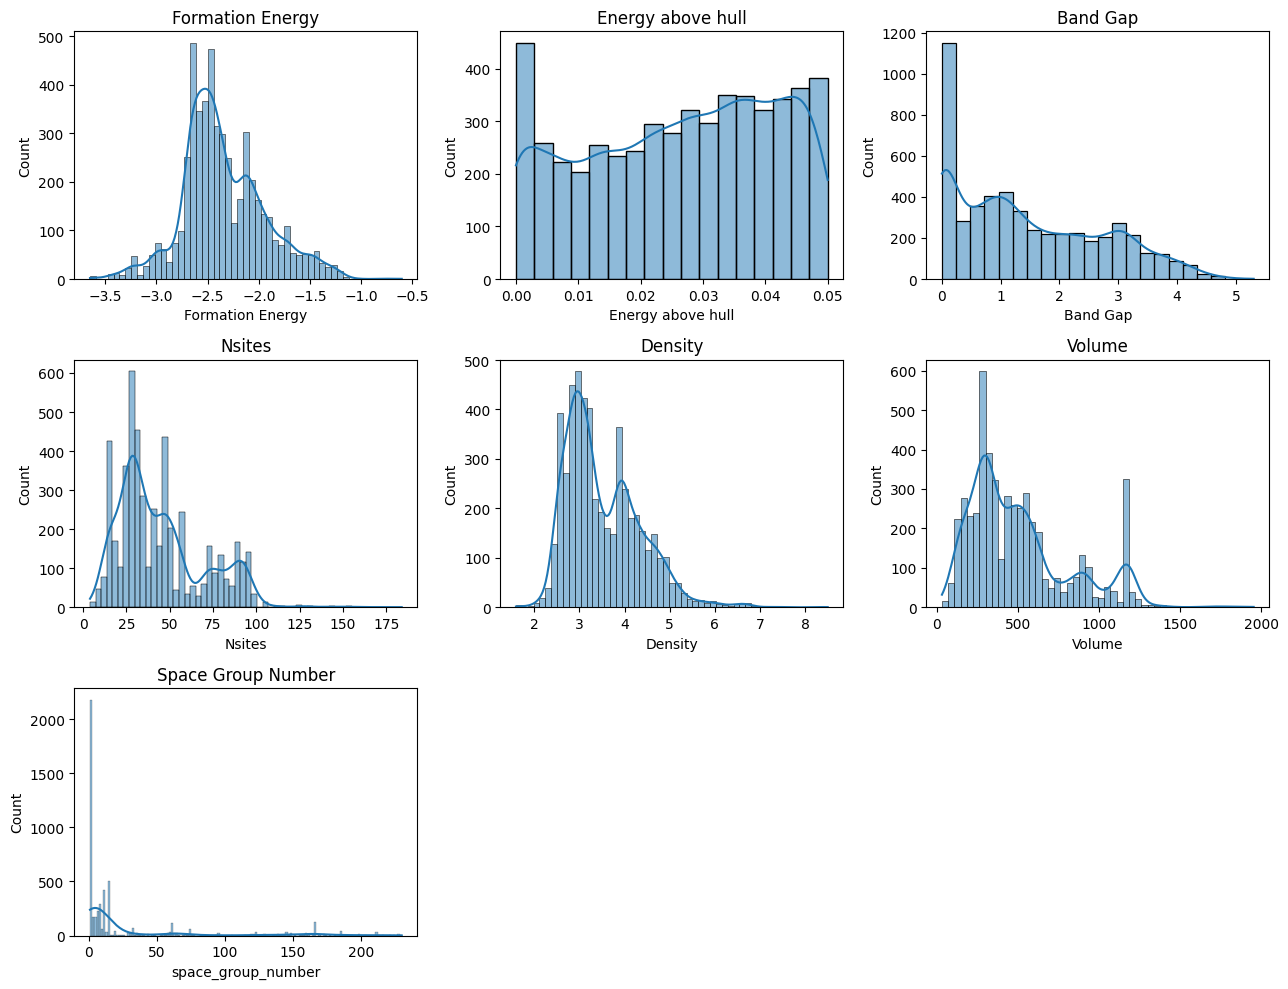

In [ ]:
# Visualize numerical features distribution
fig, axes = plt.subplots(3,3, figsize=(13,10))

sns.histplot(df["formation_energy"], kde=True, ax=axes[0,0])
axes[0,0].set_xlabel("Formation Energy")
axes[0,0].set_title("Formation Energy")

sns.histplot(df["energy_above_hull"], kde=True, ax=axes[0,1])
axes[0,1].set_xlabel("Energy above hull")
axes[0,1].set_title("Energy above hull")

sns.histplot(df["band_gap"], kde=True, ax=axes[0,2])
axes[0,2].set_xlabel("Band Gap")
axes[0,2].set_title("Band Gap")

sns.histplot(df["nsites"], kde=True, ax=axes[1,0])
axes[1,0].set_xlabel("Nsites")
axes[1,0].set_title("Nsites")

sns.histplot(df["density"], kde=True, ax=axes[1,1])
axes[1,1].set_xlabel("Density")
axes[1,1].set_title("Density")

sns.histplot(df["volume"], kde=True, ax=axes[1,2])
axes[1,2].set_xlabel("Volume")
axes[1,2].set_title("Volume")

sns.histplot(df["space_group_number"], kde=True, ax=axes[2,0])
axes[2,0].set_xlabel("space_group_number")
axes[2,0].set_title("Space Group Number")

axes[2,1].axis("off")
axes[2,2].axis("off")

plt.tight_layout()
plt.show()

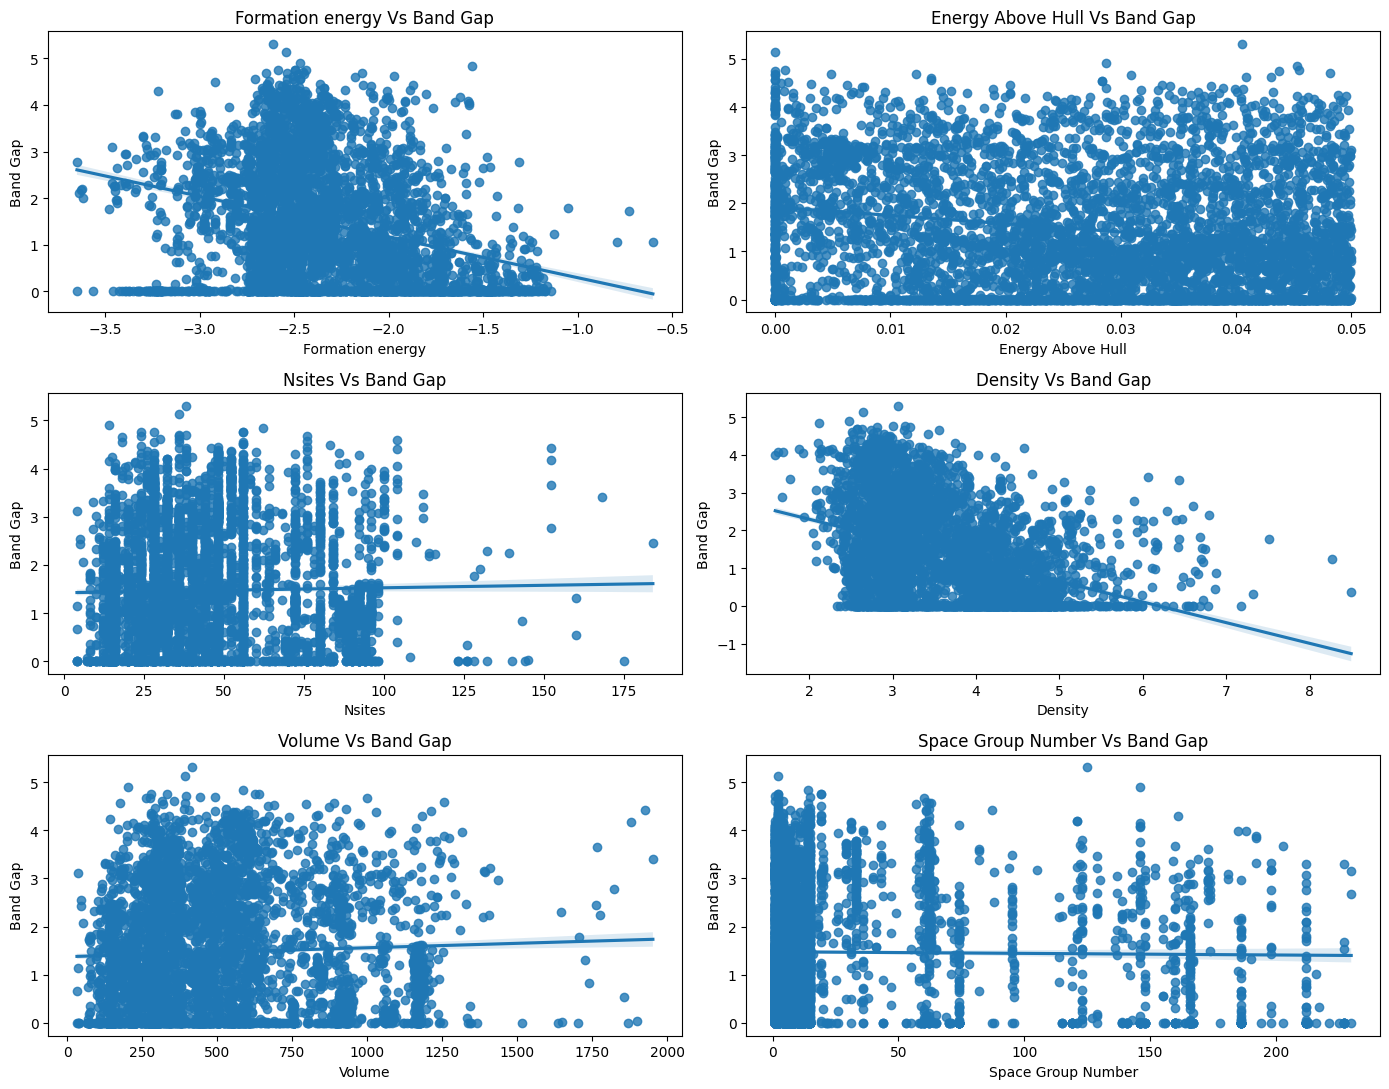

In [ ]:
fig, axes = plt.subplots(3,2, figsize=(14,11))

sns.regplot(x="formation_energy", y="band_gap", data=df, ax=axes[0,0])
axes[0,0].set_xlabel("Formation energy")
axes[0,0].set_ylabel("Band Gap")
axes[0,0].set_title("Formation energy Vs Band Gap")

sns.regplot(x="energy_above_hull", y="band_gap", data=df, ax=axes[0,1])
axes[0,1].set_xlabel("Energy Above Hull")
axes[0,1].set_ylabel("Band Gap")
axes[0,1].set_title("Energy Above Hull Vs Band Gap")

sns.regplot(x="nsites", y="band_gap", data=df, ax=axes[1,0])
axes[1,0].set_xlabel("Nsites")
axes[1,0].set_ylabel("Band Gap")
axes[1,0].set_title("Nsites Vs Band Gap")

sns.regplot(x="density", y="band_gap", data=df, ax=axes[1,1])
axes[1,1].set_xlabel("Density")
axes[1,1].set_ylabel("Band Gap")
axes[1,1].set_title("Density Vs Band Gap")

sns.regplot(x="volume", y="band_gap", data=df, ax=axes[2,0])
axes[2,0].set_xlabel("Volume")
axes[2,0].set_ylabel("Band Gap")
axes[2,0].set_title("Volume Vs Band Gap")

sns.regplot(x="space_group_number", y="band_gap", data=df, ax=axes[2,1])
axes[2,1].set_xlabel("Space Group Number")
axes[2,1].set_ylabel("Band Gap")
axes[2,1].set_title("Space Group Number Vs Band Gap")

plt.tight_layout()
plt.show()

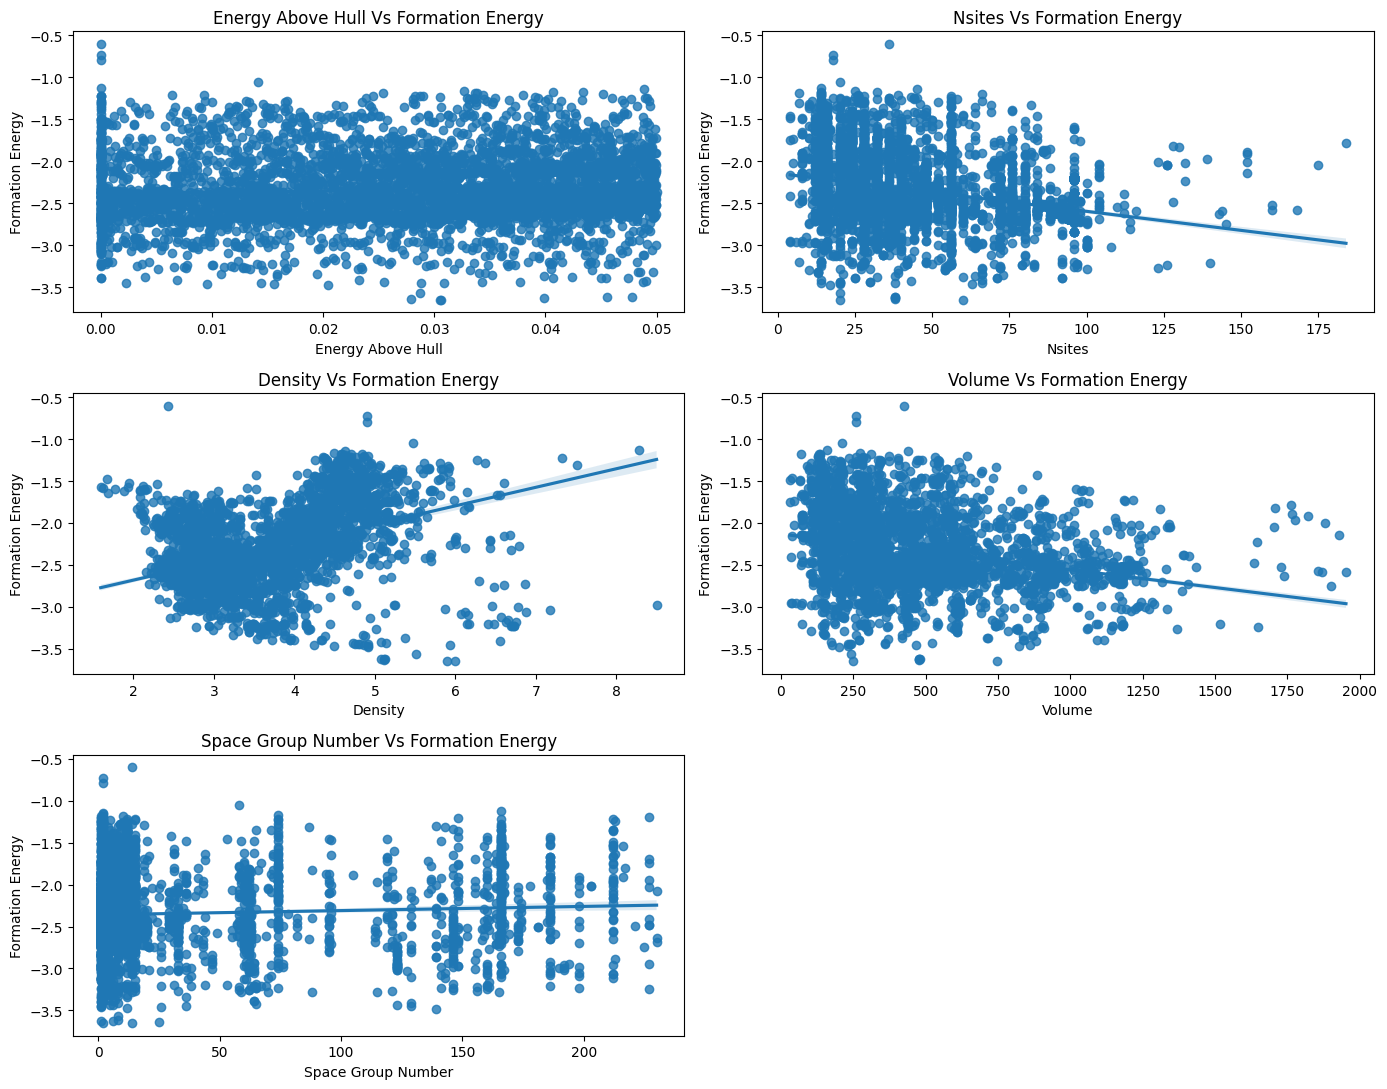

In [ ]:
fig, axes = plt.subplots(3,2, figsize=(14,11))

sns.regplot(x="energy_above_hull", y="formation_energy", data=df, ax=axes[0,0])
axes[0,0].set_xlabel("Energy Above Hull")
axes[0,0].set_ylabel("Formation Energy")
axes[0,0].set_title("Energy Above Hull Vs Formation Energy")

sns.regplot(x="nsites", y="formation_energy", data=df, ax=axes[0,1])
axes[0,1].set_xlabel("Nsites")
axes[0,1].set_ylabel("Formation Energy")
axes[0,1].set_title("Nsites Vs Formation Energy")

sns.regplot(x="density", y="formation_energy", data=df, ax=axes[1,0])
axes[1,0].set_xlabel("Density")
axes[1,0].set_ylabel("Formation Energy")
axes[1,0].set_title("Density Vs Formation Energy")

sns.regplot(x="volume", y="formation_energy", data=df, ax=axes[1,1])
axes[1,1].set_xlabel("Volume")
axes[1,1].set_ylabel("Formation Energy")
axes[1,1].set_title("Volume Vs Formation Energy")

sns.regplot(x="space_group_number", y="formation_energy", data=df, ax=axes[2,0])
axes[2,0].set_xlabel("Space Group Number")
axes[2,0].set_ylabel("Formation Energy")
axes[2,0].set_title("Space Group Number Vs Formation Energy")

axes[2,1].axis("off")

plt.tight_layout()
plt.show()

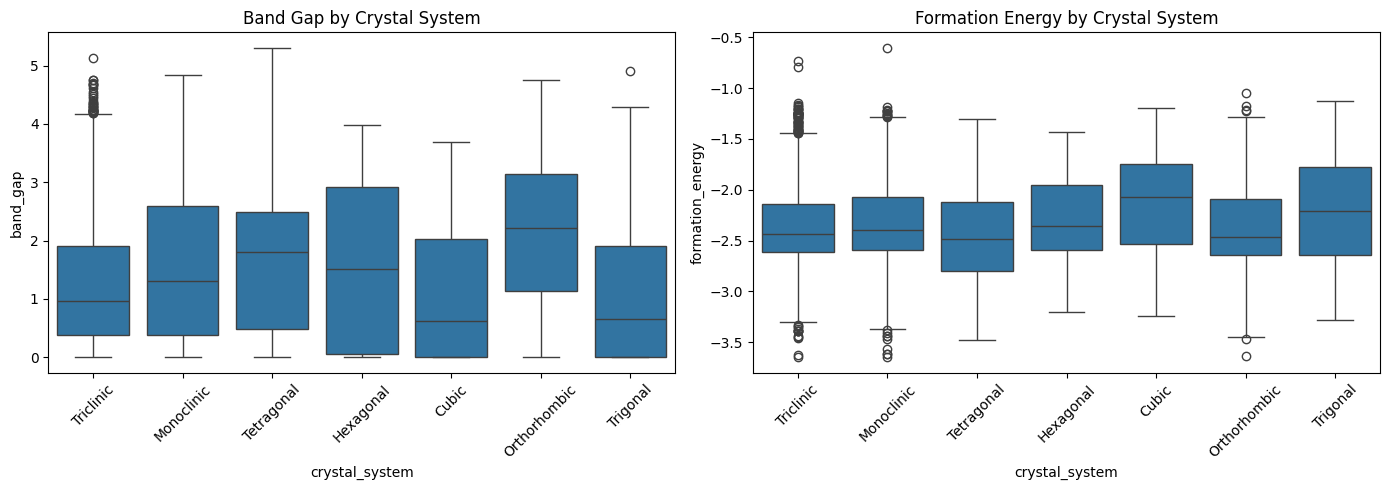

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Band Gap by Crystal System
sns.boxplot(data=df, x='crystal_system', y='band_gap', ax=axes[0])
axes[0].set_title('Band Gap by Crystal System')
axes[0].tick_params(axis='x', rotation=45)

# Formation Energy by Crystal System
sns.boxplot(data=df, x='crystal_system', y='formation_energy', ax=axes[1])
axes[1].set_title('Formation Energy by Crystal System')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Investigate the outliers

Instead of blindly removing outliers, let's see if:
- They are physically meaningful?
- They are data errors
- They are rare occurences in battery chemistry

In [ ]:
# Investigate the outliers

outlier_list = []
for crystal,group in df.groupby("crystal_system"):
  q1 = group["band_gap"].quantile(0.25)
  q3 = group["band_gap"].quantile(0.75)

  iqr = q3 - q1

  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr

  outliers = group[(group["band_gap"] < lower) | (group["band_gap"] > upper)]
  outlier_list.append(outliers)

all_outliers = pd.concat(outlier_list)
print(all_outliers.shape)
all_outliers.head(15)

(33, 12)


,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,space_group_number,elements
181,mp-1644021,Li2FeP2O7,4.3546,-2.541642,0.033236,2.754483,587.586162,48,Triclinic,P-1,2,"['Fe', 'Li', 'O', 'P']"
189,mp-695805,Li2FeP2O7,4.2456,-2.555914,0.018963,2.951705,548.325946,48,Triclinic,P-1,2,"['Fe', 'Li', 'O', 'P']"
190,mp-752657,Li2FeP2O7,4.3509,-2.543107,0.031771,2.908351,556.499641,48,Triclinic,P-1,2,"['Fe', 'Li', 'O', 'P']"
200,mp-757035,Li5FeP3O11,4.2351,-2.601704,0.049549,2.736082,436.321178,40,Triclinic,P-1,2,"['Fe', 'Li', 'O', 'P']"
205,mp-758865,Li2Fe(PO3)4,4.3957,-2.564414,0.028713,2.606632,491.307126,38,Triclinic,P-1,2,"['Fe', 'Li', 'O', 'P']"
390,mp-25393,Li2FePO4F,4.1935,-2.591687,0.040401,3.127166,390.175250,36,Triclinic,P1,1,"['F', 'Fe', 'Li', 'O', 'P']"
492,mp-754968,Li3FePCO7,4.2053,-2.336256,0.046245,2.739840,561.581680,52,Triclinic,P-1,2,"['C', 'Fe', 'Li', 'O', 'P']"
493,mp-754987,Li3FePCO7,4.2201,-2.344555,0.037946,2.718781,565.931578,52,Triclinic,P-1,2,"['C', 'Fe', 'Li', 'O', 'P']"
496,mp-755383,Li3FeP2HO8,4.2413,-2.442588,0.034161,3.162759,140.507453,15,Triclinic,P-1,2,"['Fe', 'H', 'Li', 'O', 'P']"
504,mp-770588,Li2FeH4(SO5)2,4.2418,-1.801751,0.048862,2.541077,389.319923,38,Triclinic,P-1,2,"['Fe', 'H', 'Li', 'O', 'S']"


In [ ]:
triclinic = df[df["crystal_system"] == "Triclinic"]
triclinic.head(15)

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,space_group_number,elements
0,mp-780192,Li5FeO4,2.6187,-1.994978,0.047048,2.505206,409.758452,40,Triclinic,P1,1,"['Fe', 'Li', 'O']"
8,mp-1303136,Li2FeO3,0.0652,-1.877167,0.000792,3.864279,202.353201,24,Triclinic,P-1,2,"['Fe', 'Li', 'O']"
9,mp-756356,Li8FeO6,0.3347,-1.964386,0.029307,2.678452,257.122404,30,Triclinic,P-1,2,"['Fe', 'Li', 'O']"
10,mp-756497,LiFeO2,1.4741,-1.917561,0.027376,4.143655,189.921528,20,Triclinic,P-1,2,"['Fe', 'Li', 'O']"
19,mp-1273123,Li2TiFeO4,1.2212,-2.568293,0.038553,3.884033,310.543142,32,Triclinic,P1,1,"['Fe', 'Li', 'O', 'Ti']"
20,mp-1278188,Li2TiFeO4,1.2736,-2.564606,0.042240,3.908954,308.563344,32,Triclinic,P1,1,"['Fe', 'Li', 'O', 'Ti']"
21,mp-1285010,Li2TiFeO4,1.5225,-2.570142,0.036704,3.902360,154.542362,16,Triclinic,P1,1,"['Fe', 'Li', 'O', 'Ti']"
22,mp-1301347,Li2TiFeO4,1.6269,-2.565969,0.040877,3.907811,308.653597,32,Triclinic,P1,1,"['Fe', 'Li', 'O', 'Ti']"
23,mp-1661760,Li2Mn3FeO8,0.3501,-1.977609,0.033751,4.215010,285.648532,28,Triclinic,P1,1,"['Fe', 'Li', 'Mn', 'O']"
24,mp-1982622,Li2FeP2O7,4.0783,-2.527720,0.047158,2.959258,546.926469,48,Triclinic,P1,1,"['Fe', 'Li', 'O', 'P']"


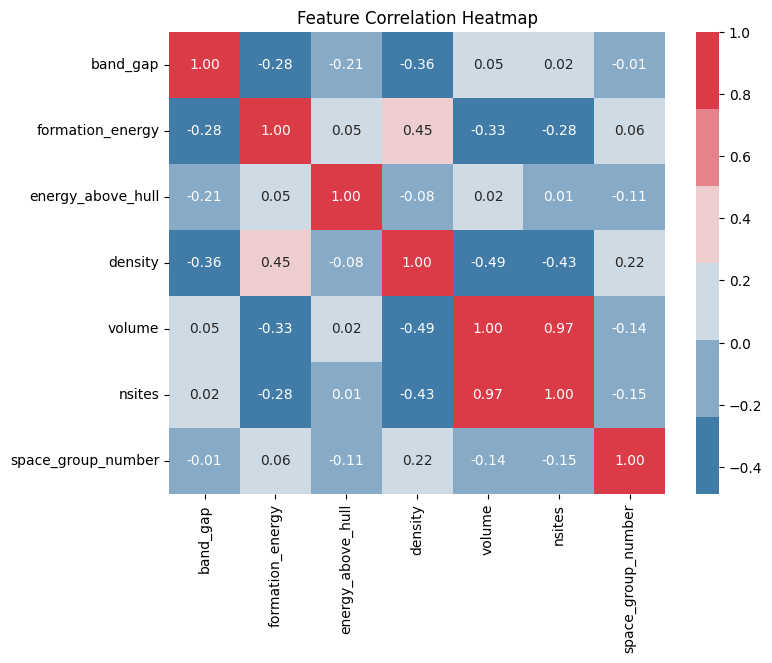

In [ ]:
# Numeric Values
Num_vals = df.select_dtypes(include=["number"]).columns.tolist()

corr_matrix = df[Num_vals].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cbar=True, cmap=sns.diverging_palette(240,10))
plt.title('Feature Correlation Heatmap')
plt.show()

### Feature Engineering

In [ ]:
# create a copy of the data
df1 = df.copy()

# Convert the formula feature into a pymatgen object
def parse_formula(formula):
  try:
    return Composition(formula)
  except Exception as e:
    print(f"Could not parse {formula} - {e}")
    return None

df1["composition"] = df1["formula"].apply(parse_formula)
# check the class of composition feature
#print(type(df1.loc[0, "composition"]))

In [ ]:
# Extract features from space group
def extract_spacegroup_features(sg_symbol):
    sg = SpaceGroup(sg_symbol)

    # inversion symmetry is embedded in point group symbol
    point_group = sg.point_group

    is_centrosymmetric = int("-" in point_group or "m" in point_group)

    return {
        "is_centrosymmetric": is_centrosymmetric,
        "symmetry_ops": len(sg.symmetry_ops),
        "symmetry_density": len(sg.symmetry_ops) / sg.int_number
    }

features = df1["space_group"].apply(extract_spacegroup_features)
sg_features_df = pd.DataFrame(features.tolist(), index=df1.index)
df1 = pd.concat([df1, sg_features_df], axis=1)

In [ ]:
df1.head()

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,space_group_number,elements,composition,is_centrosymmetric,symmetry_ops,symmetry_density
0,mp-780192,Li5FeO4,2.6187,-1.994978,0.047048,2.505206,409.758452,40,Triclinic,P1,1,"['Fe', 'Li', 'O']","(Li, Fe, O)",0,1,1.000000
1,mp-1177943,Li2FeO2,3.1408,-1.836257,0.043743,3.630131,186.130640,20,Monoclinic,C2/m,12,"['Fe', 'Li', 'O']","(Li, Fe, O)",1,8,0.666667
2,mp-887724,Li2FeO3,1.0267,-1.874446,0.003513,3.856510,202.760828,24,Monoclinic,C2/m,12,"['Fe', 'Li', 'O']","(Li, Fe, O)",1,8,0.666667
3,mp-756155,Li6FeO4,2.7019,-1.961743,0.025520,2.566594,417.920661,44,Tetragonal,P4_2/nmc,137,"['Fe', 'Li', 'O']","(Li, Fe, O)",1,16,0.116788
4,mp-1272755,Li2FeO2,3.0406,-1.835668,0.044332,3.660974,184.562545,20,Monoclinic,P2_1/c,14,"['Fe', 'Li', 'O']","(Li, Fe, O)",1,4,0.285714


In [ ]:
# Extract selected properties from composition object
properties = [
    "Electronegativity",
    "NValence",
    "NpValence",
    "NdValence",
    "NpUnfilled",
    "AtomicRadius",
    "CovalentRadius",
    "FirstIonizationEnergy",
    "MeltingT",
    "BoilingT",
    "AtomicWeight",
    "NdUnfilled",
    "GSmagmom"
]

# Initialize Featurizer with only the selected properties
ep_featurizer = ElementProperty(data_source="magpie", features=properties, stats=["mean","maximum","avg_dev"])
print("Extracting Compositional Features...")
compositional_features = ep_featurizer.featurize_dataframe(df1,col_id="composition",ignore_errors=False)
print("Extraction Completed")

Extracting Compositional Features...


ElementProperty:   0%|          | 0/5169 [00:00<?, ?it/s]

Extraction Completed


In [ ]:
# Engineer additional features
compositional_features["volume_per_atom"] = compositional_features["volume"] / compositional_features["nsites"]

In [ ]:
compositional_features.head()

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,...,MagpieData mean AtomicWeight,MagpieData maximum AtomicWeight,MagpieData avg_dev AtomicWeight,MagpieData mean NdUnfilled,MagpieData maximum NdUnfilled,MagpieData avg_dev NdUnfilled,MagpieData mean GSmagmom,MagpieData maximum GSmagmom,MagpieData avg_dev GSmagmom,volume_per_atom
0,mp-780192,Li5FeO4,2.6187,-1.994978,0.047048,2.505206,409.758452,40,Triclinic,P1,...,15.454760,55.845,8.513760,0.400000,4.0,0.720000,0.211066,2.110663,0.379919,10.243961
1,mp-1177943,Li2FeO2,3.1408,-1.836257,0.043743,3.630131,186.130640,20,Monoclinic,C2/m,...,20.345160,55.845,14.199936,0.800000,4.0,1.280000,0.422133,2.110663,0.675412,9.306532
2,mp-887724,Li2FeO3,1.0267,-1.874446,0.003513,3.856510,202.760828,24,Monoclinic,C2/m,...,19.620867,55.845,12.074711,0.666667,4.0,1.111111,0.351777,2.110663,0.586295,8.448368
3,mp-756155,Li6FeO4,2.7019,-1.961743,0.025520,2.566594,417.920661,44,Tetragonal,P4_2/nmc,...,14.680782,55.845,8.443398,0.363636,4.0,0.661157,0.191878,2.110663,0.348870,9.498197
4,mp-1272755,Li2FeO2,3.0406,-1.835668,0.044332,3.660974,184.562545,20,Monoclinic,P2_1/c,...,20.345160,55.845,14.199936,0.800000,4.0,1.280000,0.422133,2.110663,0.675412,9.228127


In [ ]:
# Separate dataset for Formation energy and bandgap

formation_energy_df = compositional_features.copy()
band_gap_df = compositional_features.copy()

### Formation Energy

In [ ]:
fe_df = formation_energy_df.copy()
# Group-split the dataset by the formula feature into train and test sets

fe_groups = fe_df["formula"]
fe_splitter = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
fe_train_idx, fe_test_idx = next(fe_splitter.split(fe_df, groups=fe_groups))
fe_train_df = fe_df.iloc[fe_train_idx]
fe_test_df = fe_df.iloc[fe_test_idx]

In [ ]:
#check for overlapping materials
fe_train_formulas = set(fe_train_df["formula"])
fe_test_formulas = set(fe_test_df["formula"])

fe_overlap = fe_train_formulas.intersection(fe_test_formulas)
print(len(fe_overlap))

0


In [ ]:
fe_train_df.head()

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,...,MagpieData mean AtomicWeight,MagpieData maximum AtomicWeight,MagpieData avg_dev AtomicWeight,MagpieData mean NdUnfilled,MagpieData maximum NdUnfilled,MagpieData avg_dev NdUnfilled,MagpieData mean GSmagmom,MagpieData maximum GSmagmom,MagpieData avg_dev GSmagmom,volume_per_atom
0,mp-780192,Li5FeO4,2.6187,-1.994978,0.047048,2.505206,409.758452,40,Triclinic,P1,...,15.454760,55.845,8.513760,0.400000,4.0,0.720000,0.211066,2.110663,0.379919,10.243961
1,mp-1177943,Li2FeO2,3.1408,-1.836257,0.043743,3.630131,186.130640,20,Monoclinic,C2/m,...,20.345160,55.845,14.199936,0.800000,4.0,1.280000,0.422133,2.110663,0.675412,9.306532
2,mp-887724,Li2FeO3,1.0267,-1.874446,0.003513,3.856510,202.760828,24,Monoclinic,C2/m,...,19.620867,55.845,12.074711,0.666667,4.0,1.111111,0.351777,2.110663,0.586295,8.448368
4,mp-1272755,Li2FeO2,3.0406,-1.835668,0.044332,3.660974,184.562545,20,Monoclinic,P2_1/c,...,20.345160,55.845,14.199936,0.800000,4.0,1.280000,0.422133,2.110663,0.675412,9.228127
5,mp-770834,Li5FeO4,2.8302,-1.996122,0.045904,2.521237,407.153089,40,Monoclinic,P2_1/c,...,15.454760,55.845,8.513760,0.400000,4.0,0.720000,0.211066,2.110663,0.379919,10.178827


In [ ]:
final_test_df = fe_test_df[["material_id","formula"]].copy()
final_test_df["band_gap"] = 0
final_test_df["formation_energy"] = 0
final_test_df.head()

,material_id,formula,band_gap,formation_energy
3,mp-756155,Li6FeO4,0,0
32,mp-759547,Li4FeCo9O20,0,0
42,mp-1177788,Li2VFeO4,0,0
50,mp-705356,Li2Fe(PO3)5,0,0
113,mp-770764,Li2Fe(BO2)5,0,0


In [ ]:
# One-hot encode crystal system

fe_crystal_system_encoder = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")
fe_train_enc_array = fe_crystal_system_encoder.fit_transform(fe_train_df[["crystal_system"]])
fe_train_enc = pd.DataFrame(fe_train_enc_array, columns=fe_crystal_system_encoder.get_feature_names_out(["crystal_system"]), index=fe_train_df.index)
fe_train_enc_df = pd.concat([fe_train_df.drop(columns=["crystal_system"]), fe_train_enc], axis=1)

fe_test_enc_array = fe_crystal_system_encoder.transform(fe_test_df[["crystal_system"]])
fe_test_enc = pd.DataFrame(fe_test_enc_array, columns=fe_crystal_system_encoder.get_feature_names_out(["crystal_system"]), index=fe_test_df.index)
fe_test_enc_df = pd.concat([fe_test_df.drop(columns=["crystal_system"]), fe_test_enc], axis=1)


In [ ]:
fe_train_enc_df.head()

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,space_group,space_group_number,...,MagpieData mean GSmagmom,MagpieData maximum GSmagmom,MagpieData avg_dev GSmagmom,volume_per_atom,crystal_system_Hexagonal,crystal_system_Monoclinic,crystal_system_Orthorhombic,crystal_system_Tetragonal,crystal_system_Triclinic,crystal_system_Trigonal
0,mp-780192,Li5FeO4,2.6187,-1.994978,0.047048,2.505206,409.758452,40,P1,1,...,0.211066,2.110663,0.379919,10.243961,0.0,0.0,0.0,0.0,1.0,0.0
1,mp-1177943,Li2FeO2,3.1408,-1.836257,0.043743,3.630131,186.130640,20,C2/m,12,...,0.422133,2.110663,0.675412,9.306532,0.0,1.0,0.0,0.0,0.0,0.0
2,mp-887724,Li2FeO3,1.0267,-1.874446,0.003513,3.856510,202.760828,24,C2/m,12,...,0.351777,2.110663,0.586295,8.448368,0.0,1.0,0.0,0.0,0.0,0.0
4,mp-1272755,Li2FeO2,3.0406,-1.835668,0.044332,3.660974,184.562545,20,P2_1/c,14,...,0.422133,2.110663,0.675412,9.228127,0.0,1.0,0.0,0.0,0.0,0.0
5,mp-770834,Li5FeO4,2.8302,-1.996122,0.045904,2.521237,407.153089,40,P2_1/c,14,...,0.211066,2.110663,0.379919,10.178827,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
# Remove targets
#train_bandgap = train_enc_df["band_gap"]
# log_transform train_bandgap
#Train_bandgap = np.log1p(train_bandgap)
train_formation_energy = fe_train_enc_df["formation_energy"]

#test_bandgap = test_enc_df["band_gap"]
#Test_bandgap = np.log1p(test_bandgap)
test_formation_energy = fe_test_enc_df["formation_energy"]

fe_Train_df = fe_train_enc_df.drop(columns=["material_id","formula","band_gap","formation_energy","space_group","composition","elements"], axis=1)
fe_Test_df = fe_test_enc_df.drop(columns=["material_id","formula","band_gap","formation_energy","space_group","composition","elements"], axis=1)

print("Train_df shape", fe_Train_df.shape)
print("Test_df shape", fe_Test_df.shape)
print("Train_formation_energy shape", train_formation_energy.shape)
print("Test_formation_energy shape", test_formation_energy.shape)


Train_df shape (4653, 54)
Test_df shape (516, 54)
Train_formation_energy shape (4653,)
Test_formation_energy shape (516,)


In [ ]:
def rf_objective_formation_energy(trial):
    fe_params = {
        "max_depth":trial.suggest_int("max_depth",10,30),
        "n_estimators":trial.suggest_int("n_estimators",100,1000),
        "min_samples_split":trial.suggest_int("min_sample_split",2,5),
        "min_samples_leaf":trial.suggest_int("min_sample_leaf",1,5),
        "random_state": trial.suggest_int("random_state",1,100)
    }

    rf = RandomForestRegressor(**fe_params)
    rf.fit(fe_Train_df, train_formation_energy)
    fe_pred = rf.predict(fe_Test_df)

    return r2_score(test_formation_energy, fe_pred)


fe_rf_study = optuna.create_study(direction="maximize",study_name="fe_rf_optimizer")
fe_rf_study.optimize(rf_objective_formation_energy,n_trials=100)

print('Best parameters', fe_rf_study.best_params)
print('Best value', fe_rf_study.best_value)

[I 2026-05-25 13:43:22,866] A new study created in memory with name: fe_rf_optimizer
[I 2026-05-25 13:43:55,743] Trial 0 finished with value: 0.9657482459163933 and parameters: {'max_depth': 17, 'n_estimators': 507, 'min_sample_split': 3, 'min_sample_leaf': 3, 'random_state': 18}. Best is trial 0 with value: 0.9657482459163933.
[I 2026-05-25 13:44:24,934] Trial 1 finished with value: 0.9693776465900724 and parameters: {'max_depth': 21, 'n_estimators': 408, 'min_sample_split': 4, 'min_sample_leaf': 1, 'random_state': 54}. Best is trial 1 with value: 0.9693776465900724.
[I 2026-05-25 13:45:10,010] Trial 2 finished with value: 0.9656790766722354 and parameters: {'max_depth': 21, 'n_estimators': 661, 'min_sample_split': 5, 'min_sample_leaf': 3, 'random_state': 51}. Best is trial 1 with value: 0.9693776465900724.
[I 2026-05-25 13:46:08,728] Trial 3 finished with value: 0.9660679254156329 and parameters: {'max_depth': 16, 'n_estimators': 909, 'min_sample_split': 2, 'min_sample_leaf': 3, 'ran

KeyboardInterrupt: 

In [ ]:
def xgb_objective_formation_energy(trial):
    fe_xgb_params = {
        'max_depth': trial.suggest_int('max_depth', 10, 50),
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.1),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        #'min_child_weight': trial.suggest_int('min_child_weight', 1, 3),
        #'gamma': trial.suggest_float('gamma', 0.01, 1.0),
        #'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1.0, 4.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1.0, 4.0),
        'random_state': trial.suggest_int('random_state', 1, 100)
    }
    fe_boost = XGBRegressor(**fe_xgb_params)
    fe_boost.fit(fe_Train_df, train_formation_energy)
    fe_xgb_pred = fe_boost.predict(fe_Test_df)
    return r2_score(test_formation_energy, fe_xgb_pred)

fe_xgb_study = optuna.create_study(direction='maximize', study_name="xgb_optimizer")
fe_xgb_study.optimize(xgb_objective_formation_energy, n_trials=100)

print('Best parameters', fe_xgb_study.best_params)
print('Best value', fe_xgb_study.best_value)



[I 2026-05-24 19:09:52,079] A new study created in memory with name: xgb_optimizer
[I 2026-05-24 19:10:10,127] Trial 0 finished with value: 0.965405667204929 and parameters: {'max_depth': 29, 'learning_rate': 0.014208310263158132, 'n_estimators': 611, 'reg_alpha': 2.711389942094895, 'reg_lambda': 3.519528577740819, 'random_state': 71}. Best is trial 0 with value: 0.965405667204929.
[I 2026-05-24 19:10:22,518] Trial 1 finished with value: 0.9758435042783786 and parameters: {'max_depth': 28, 'learning_rate': 0.05290880180801906, 'n_estimators': 826, 'reg_alpha': 1.2172755227164505, 'reg_lambda': 3.530113468335217, 'random_state': 28}. Best is trial 1 with value: 0.9758435042783786.
[I 2026-05-24 19:10:37,299] Trial 2 finished with value: 0.9672802696314217 and parameters: {'max_depth': 32, 'learning_rate': 0.02420168343997212, 'n_estimators': 796, 'reg_alpha': 3.744969400551248, 'reg_lambda': 3.487062404211979, 'random_state': 12}. Best is trial 1 with value: 0.9758435042783786.
[I 2026-

Best parameters {'max_depth': 14, 'learning_rate': 0.08867801255005228, 'n_estimators': 646, 'reg_alpha': 1.0022234515309496, 'reg_lambda': 3.9124963651418514, 'random_state': 26}
Best value 0.9785497614678925


In [ ]:
def catboost_objective_formation_energy(trial):
    fe_cat_params = {
        'depth':            trial.suggest_int('depth', 4, 10),
        'learning_rate':    trial.suggest_float('learning_rate', 0.001, 0.1),
        'iterations':       trial.suggest_int('iterations', 100, 1000),
        'l2_leaf_reg':      trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'border_count':     trial.suggest_int('border_count', 32, 255),
        'random_strength':  trial.suggest_float('random_strength', 0.0, 10.0),
        'random_seed':      trial.suggest_int('random_seed', 1, 100),
        'verbose':          0
    }
    fe_cat = CatBoostRegressor(**fe_cat_params)
    fe_cat.fit(fe_Train_df, train_formation_energy)
    fe_cat_pred = fe_cat.predict(fe_Test_df)

    return r2_score(test_formation_energy, fe_cat_pred)


fe_cat_study = optuna.create_study(
    direction='maximize',
    study_name='catboost_fe_optimizer'
)

fe_cat_study.optimize(catboost_objective_formation_energy, n_trials=100)

print('Best parameters:', fe_cat_study.best_params)
print('Best R² value:',   fe_cat_study.best_value)

[I 2026-05-24 19:55:09,052] A new study created in memory with name: catboost_fe_optimizer
[I 2026-05-24 19:55:09,960] Trial 0 finished with value: 0.9698299868027923 and parameters: {'depth': 4, 'learning_rate': 0.08956923749980437, 'iterations': 218, 'l2_leaf_reg': 9.02128026728714, 'bagging_temperature': 0.8017538149747023, 'border_count': 208, 'random_strength': 1.7534647780005952, 'random_seed': 70}. Best is trial 0 with value: 0.9698299868027923.
[I 2026-05-24 19:55:11,701] Trial 1 finished with value: 0.9190254491575638 and parameters: {'depth': 4, 'learning_rate': 0.013011511647988812, 'iterations': 431, 'l2_leaf_reg': 3.6953038192980805, 'bagging_temperature': 0.31511871120114743, 'border_count': 253, 'random_strength': 5.004568271136512, 'random_seed': 47}. Best is trial 0 with value: 0.9698299868027923.
[I 2026-05-24 19:55:22,605] Trial 2 finished with value: 0.7832575747173529 and parameters: {'depth': 10, 'learning_rate': 0.00928814579994788, 'iterations': 151, 'l2_leaf_re

Best parameters: {'depth': 6, 'learning_rate': 0.06971657856153801, 'iterations': 893, 'l2_leaf_reg': 4.069152717195301, 'bagging_temperature': 0.5623118621923068, 'border_count': 118, 'random_strength': 4.234424969208655, 'random_seed': 26}
Best R² value: 0.9883925277359231


In [ ]:
#optimized RF for formation energy
fe_rf = RandomForestRegressor(max_depth=29, n_estimators=120, min_samples_split=2, min_samples_leaf=1, random_state=44)
fe_rf.fit(fe_Train_df, train_formation_energy)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",120
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",29
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [ ]:
#Make predictions and evaluate model performance
# make predictions
fe_rf_pred_tr = fe_rf.predict(fe_Train_df)
fe_r2_tr = r2_score(train_formation_energy, fe_rf_pred_tr)
fe_mse_tr = mean_squared_error(train_formation_energy, fe_rf_pred_tr)
fe_mae_tr = mean_absolute_error(train_formation_energy, fe_rf_pred_tr)

print("Formation Energy Train_R2: ", fe_r2_tr)
print("Formation Energy Train_MSE: ", fe_mse_tr)
print("Formation Energy Train_MAE: ", fe_mae_tr)

Formation Energy Train_R2:  0.996534536091411
Formation Energy Train_MSE:  0.000554250006888559
Formation Energy Train_MAE:  0.009211593768444845


In [ ]:
#Make predictions and evaluate model performance
# make predictions
fe_rf_pred = fe_rf.predict(fe_Test_df)
fe_r2 = r2_score(test_formation_energy, fe_rf_pred)
fe_mse = mean_squared_error(test_formation_energy, fe_rf_pred)
fe_mae = mean_absolute_error(test_formation_energy, fe_rf_pred)

print("Formation Energy R2: ", fe_r2)
print("Formation Energy MSE: ", fe_mse)
print("Formation Energy MAE: ", fe_mae)

Formation Energy R2:  0.9723116036434778
Formation Energy MSE:  0.004997044661772314
Formation Energy MAE:  0.04137810757154579


In [ ]:
fe_xgb = XGBRegressor(max_depth=14, learning_rate=0.08867801255005228, n_estimators=646, reg_alpha=1.0022234515309496,
                      reg_lambda=3.9124963651418514, random_state=26)
fe_xgb.fit(fe_Train_df, train_formation_energy)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [ ]:
fe_xgb_pred_tr = fe_xgb.predict(fe_Train_df)
fe_xgb_r2_tr = r2_score(train_formation_energy, fe_xgb_pred_tr)
fe_xgb_mse_tr = mean_squared_error(train_formation_energy, fe_xgb_pred_tr)
fe_xgb_mae_tr = mean_absolute_error(train_formation_energy, fe_xgb_pred_tr)

print("Formation Energy Train_R2: ", fe_xgb_r2_tr)
print("Formation Energy Train_MSE: ", fe_xgb_mse_tr)
print("Formation Energy Train_MAE: ", fe_xgb_mae_tr)

Formation Energy Train_R2:  0.9971375397880673
Formation Energy Train_MSE:  0.00045780843027964045
Formation Energy Train_MAE:  0.010289467029435206


In [ ]:
fe_xgb_pred = fe_xgb.predict(fe_Test_df)
fe_xgb_r2 = r2_score(test_formation_energy, fe_xgb_pred)
fe_xgb_mse = mean_squared_error(test_formation_energy, fe_xgb_pred)
fe_xgb_mae = mean_absolute_error(test_formation_energy, fe_xgb_pred)

print("Formation Energy R2: ", fe_xgb_r2)
print("Formation Energy MSE: ", fe_xgb_mse)
print("Formation Energy MAE: ", fe_xgb_mae)

Formation Energy R2:  0.9797168597029304
Formation Energy MSE:  0.003660586067909834
Formation Energy MAE:  0.03909792597104849


In [ ]:
fe_cbt = CatBoostRegressor(depth=6, learning_rate=0.06971657856153801, iterations=893, l2_leaf_reg=4.069152717195301,
                           bagging_temperature=0.5623118621923068, border_count=118, random_strength=4.234424969208655,
                           random_seed=26, verbose=0)
fe_cbt.fit(fe_Train_df, train_formation_energy)

CatBoostRegressor(bagging_temperature=0.5623118621923068, border_count=118, depth=6, iterations=893, l2_leaf_reg=4.069152717195301, learning_rate=0.06971657856153801, loss_function='RMSE', random_seed=26, random_strength=4.234424969208655, verbose=0)

In [ ]:
fe_cbt_pred_tr = fe_cbt.predict(fe_Train_df)
fe_cbt_r2_tr = r2_score(train_formation_energy, fe_cbt_pred_tr)
fe_cbt_mse_tr = mean_squared_error(train_formation_energy, fe_cbt_pred_tr)
fe_cbt_mae_tr = mean_absolute_error(train_formation_energy, fe_cbt_pred_tr)

print("Formation Energy R2: ", fe_cbt_r2_tr)
print("Formation Energy MSE: ", fe_cbt_mse_tr)
print("Formation Energy MAE: ", fe_cbt_mae_tr)

Formation Energy R2:  0.9982288305576854
Formation Energy MSE:  0.00028327251458906645
Formation Energy MAE:  0.011229940860803433


In [ ]:
fe_cbt_pred = fe_cbt.predict(fe_Test_df)
fe_cbt_r2 = r2_score(test_formation_energy, fe_cbt_pred)
fe_cbt_mse = mean_squared_error(test_formation_energy, fe_cbt_pred)
fe_cbt_mae = mean_absolute_error(test_formation_energy, fe_cbt_pred)

print("Formation Energy R2: ", fe_cbt_r2)
print("Formation Energy MSE: ", fe_cbt_mse)
print("Formation Energy MAE: ", fe_cbt_mae)

Formation Energy R2:  0.9883925277359231
Formation Energy MSE:  0.002094850729779179
Formation Energy MAE:  0.03042109203871698


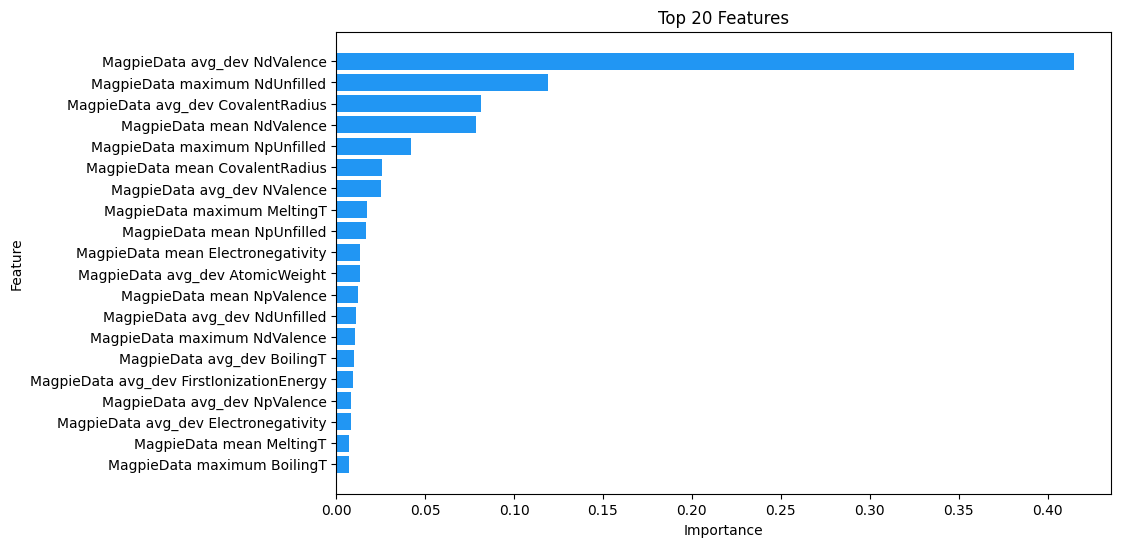

In [ ]:
visualize_feature_importance(fe_rf, fe_Train_df.columns, 20, "#2196F3")

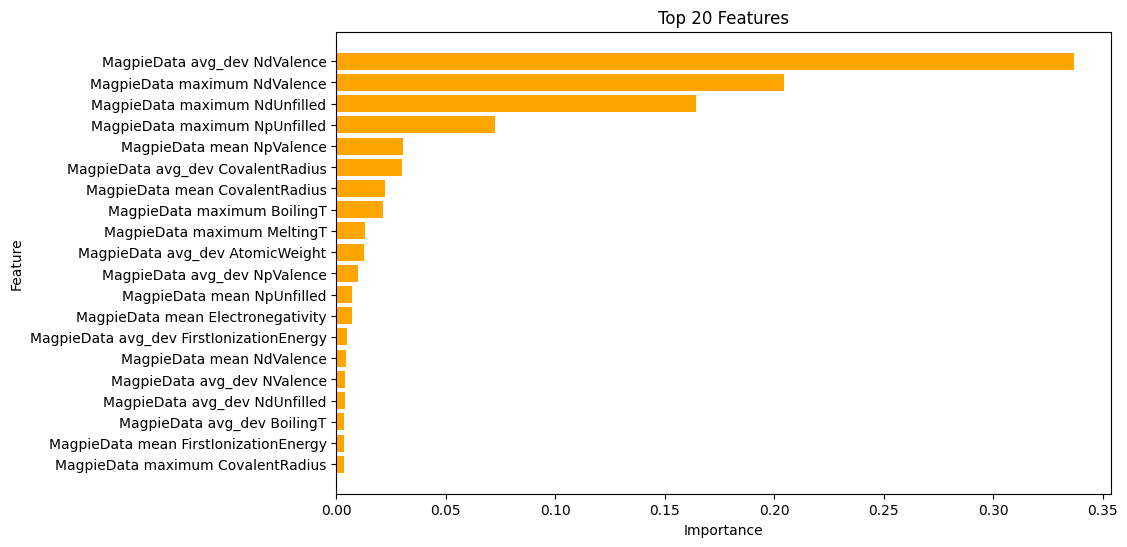

In [ ]:
#xgb feature importance
visualize_feature_importance(fe_xgb, fe_Train_df.columns, 20, "orange")

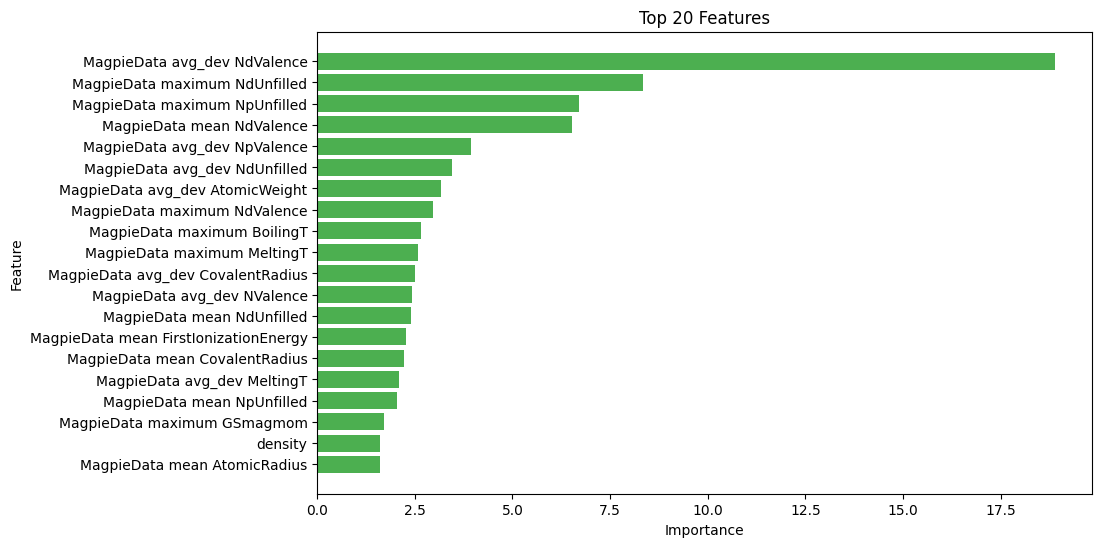

In [ ]:
#catboost feature importance
visualize_feature_importance(fe_cbt, fe_Train_df.columns, 20, "#4CAF50")

['energy_above_hull', 'density', 'volume', 'nsites',
       'space_group_number', 'is_centrosymmetric', 'symmetry_ops',
       'symmetry_density', 'MagpieData mean Electronegativity',
       'MagpieData avg_dev Electronegativity', 'MagpieData mean NValence',
       'MagpieData avg_dev NValence', 'MagpieData mean AtomicRadius',
       'MagpieData avg_dev AtomicRadius',
       'MagpieData mean FirstIonizationEnergy',
       'MagpieData avg_dev FirstIonizationEnergy', 'MagpieData mean MeltingT',
       'MagpieData avg_dev MeltingT', 'MagpieData mean AtomicWeight',
       'MagpieData avg_dev AtomicWeight', 'MagpieData mean NdUnfilled',
       'MagpieData avg_dev NdUnfilled', 'crystal_system_Hexagonal',
       'crystal_system_Monoclinic', 'crystal_system_Orthorhombic',
       'crystal_system_Tetragonal', 'crystal_system_Triclinic',
       'crystal_system_Trigonal']


       Training RF and XGB with these set of features produced the following result

       Rf: Band Gap R2:  -0.1849803967697028
           Band Gap MSE:  0.8528993408947656
           Band Gap MAE:  0.6936198352713179

      XGB: Band Gap R2:  -0.01905604075905365
           Band Gap MSE:  0.9501618326840984
           Band Gap MAE:  0.7287236901131956

### Band Gap

In [ ]:
band_gap_df.head(3)

,material_id,formula,band_gap,formation_energy,energy_above_hull,density,volume,nsites,crystal_system,space_group,...,MagpieData mean AtomicWeight,MagpieData maximum AtomicWeight,MagpieData avg_dev AtomicWeight,MagpieData mean NdUnfilled,MagpieData maximum NdUnfilled,MagpieData avg_dev NdUnfilled,MagpieData mean GSmagmom,MagpieData maximum GSmagmom,MagpieData avg_dev GSmagmom,volume_per_atom
0,mp-780192,Li5FeO4,2.6187,-1.994978,0.047048,2.505206,409.758452,40,Triclinic,P1,...,15.454760,55.845,8.513760,0.400000,4.0,0.720000,0.211066,2.110663,0.379919,10.243961
1,mp-1177943,Li2FeO2,3.1408,-1.836257,0.043743,3.630131,186.130640,20,Monoclinic,C2/m,...,20.345160,55.845,14.199936,0.800000,4.0,1.280000,0.422133,2.110663,0.675412,9.306532
2,mp-887724,Li2FeO3,1.0267,-1.874446,0.003513,3.856510,202.760828,24,Monoclinic,C2/m,...,19.620867,55.845,12.074711,0.666667,4.0,1.111111,0.351777,2.110663,0.586295,8.448368


#### More feature engineering for bandgap

In [ ]:
from pymatgen.core.periodic_table import Element

# ============================================
# Transition-Metal-Specific Features
# ============================================

def extract_tm_features(comp):

    # get only transition metals
    tm_elements = [el for el in comp.elements if el.is_transition_metal]

    # return NaN if no TM present
    if len(tm_elements) == 0:
        return {
            "tm_electronegativity": np.nan,
            "tm_atomic_radius": np.nan,
            "tm_d_valence": np.nan,
            "tm_oxidation_state": np.nan
        }

    # weighted fractions
    total_tm_fraction = sum(comp.get_atomic_fraction(el) for el in tm_elements)

    tm_X = 0
    tm_radius = 0
    tm_dval = 0

    for el in tm_elements:

        frac = comp.get_atomic_fraction(el) / total_tm_fraction

        # electronegativity
        tm_X += (el.X or 0) * frac

        # atomic radius
        radius = el.atomic_radius
        radius = float(radius) if radius else 0
        tm_radius += radius * frac

        # d-valence electrons
        try:
            d_val = el.full_electronic_structure[-1][2]
        except:
            d_val = 0

        tm_dval += d_val * frac

    # oxidation state estimate
    try:
        oxi = comp.oxi_state_guesses()
        if len(oxi) > 0:

            tm_oxi_states = []

            for el in tm_elements:
                if str(el) in oxi[0]:
                    tm_oxi_states.append(oxi[0][str(el)])

            tm_oxidation = np.mean(tm_oxi_states)

        else:
            tm_oxidation = np.nan

    except:
        tm_oxidation = np.nan

    return {
        "tm_electronegativity": tm_X,
        "tm_atomic_radius": tm_radius,
        "tm_d_valence": tm_dval,
        "tm_oxidation_state": tm_oxidation
    }

In [ ]:
# Apply TM Feature Extraction

print("Extracting transition-metal-specific features...")

tm_features = band_gap_df["composition"].apply(extract_tm_features)

tm_features_df = pd.DataFrame(
    tm_features.tolist(),
    index=df1.index
)

print("TM feature extraction completed.")

Extracting transition-metal-specific features...
TM feature extraction completed.


In [ ]:
tm_features_df["tm_oxidation_state"] = tm_features_df["tm_oxidation_state"].fillna(tm_features_df["tm_oxidation_state"].median())

In [ ]:
# merge back into dataframe
Band_gap_df = pd.concat([band_gap_df, tm_features_df], axis=1)

In [ ]:
bg_df = Band_gap_df.copy()
# Group-split the dataset by the formula feature into train and test sets

bg_groups = bg_df["formula"]
bg_splitter = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
bg_train_idx, bg_test_idx = next(bg_splitter.split(bg_df, groups=bg_groups))
bg_train_df = bg_df.iloc[bg_train_idx]
bg_test_df = bg_df.iloc[bg_test_idx]

In [ ]:
#check for overlapping materials
bg_train_formulas = set(bg_train_df["formula"])
bg_test_formulas = set(bg_test_df["formula"])

bg_overlap = bg_train_formulas.intersection(bg_test_formulas)
print(len(bg_overlap))

0


In [ ]:
# One-hot encode crystal systems

bg_crystal_system_encoder = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")
bg_train_enc_array = bg_crystal_system_encoder.fit_transform(bg_train_df[["crystal_system"]])
bg_train_enc = pd.DataFrame(bg_train_enc_array, columns=bg_crystal_system_encoder.get_feature_names_out(["crystal_system"]), index=bg_train_df.index)
bg_train_enc_df = pd.concat([bg_train_df.drop(columns=["crystal_system"]), bg_train_enc], axis=1)

bg_test_enc_array = bg_crystal_system_encoder.transform(bg_test_df[["crystal_system"]])
bg_test_enc = pd.DataFrame(bg_test_enc_array, columns=bg_crystal_system_encoder.get_feature_names_out(["crystal_system"]), index=bg_test_df.index)
bg_test_enc_df = pd.concat([bg_test_df.drop(columns=["crystal_system"]), bg_test_enc], axis=1)


In [ ]:
# Remove targets
train_bandgap = bg_train_enc_df["band_gap"]
# log_transform train_bandgap
Train_bandgap = np.log1p(train_bandgap)

test_bandgap = bg_test_enc_df["band_gap"]
Test_bandgap = np.log1p(test_bandgap)

bg_Train_df = bg_train_enc_df.drop(columns=["material_id","formula","band_gap","formation_energy","space_group","composition","elements"], axis=1)
bg_Test_df = bg_test_enc_df.drop(columns=["material_id","formula","band_gap","formation_energy","space_group","composition","elements"], axis=1)

print("Train_df shape", bg_Train_df.shape)
print("Test_df shape", bg_Test_df.shape)
print("Train_bandgap shape", Train_bandgap.shape)
print("Test_bandgap shape", Test_bandgap.shape)


Train_df shape (4653, 58)
Test_df shape (516, 58)
Train_bandgap shape (4653,)
Test_bandgap shape (516,)


In [ ]:
def rf_objective_bandgap(trial):
    params = {
        "max_depth":trial.suggest_int("max_depth",10,60),
        "n_estimators":trial.suggest_int("n_estimators",100,500),
        "min_samples_split":trial.suggest_int("min_sample_split",2,5),
        "min_samples_leaf":trial.suggest_int("min_sample_leaf",1,5),
        "random_state": trial.suggest_int("random_state",1,100)
    }

    rf = RandomForestRegressor(**params)
    rf.fit(bg_Train_df, Train_bandgap)
    rf_bg_pred = rf.predict(bg_Test_df)

    return r2_score(Test_bandgap, rf_bg_pred)


bg_rf_study = optuna.create_study(direction="maximize",study_name="rf_optimizer")
bg_rf_study.optimize(rf_objective_bandgap,n_trials=100)

print('Best parameters', bg_rf_study.best_params)
print('Best value', bg_rf_study.best_value)

[I 2026-05-25 12:25:56,341] A new study created in memory with name: rf_optimizer
[I 2026-05-25 12:26:11,991] Trial 0 finished with value: 0.5971197687497849 and parameters: {'max_depth': 56, 'n_estimators': 232, 'min_sample_split': 5, 'min_sample_leaf': 4, 'random_state': 32}. Best is trial 0 with value: 0.5971197687497849.
[I 2026-05-25 12:26:37,068] Trial 1 finished with value: 0.5920701584465826 and parameters: {'max_depth': 13, 'n_estimators': 392, 'min_sample_split': 5, 'min_sample_leaf': 4, 'random_state': 47}. Best is trial 0 with value: 0.5971197687497849.
[I 2026-05-25 12:26:52,391] Trial 2 finished with value: 0.6034987001199157 and parameters: {'max_depth': 45, 'n_estimators': 182, 'min_sample_split': 3, 'min_sample_leaf': 1, 'random_state': 66}. Best is trial 2 with value: 0.6034987001199157.
[I 2026-05-25 12:27:15,975] Trial 3 finished with value: 0.5924175603939644 and parameters: {'max_depth': 60, 'n_estimators': 308, 'min_sample_split': 5, 'min_sample_leaf': 2, 'random

Best parameters {'max_depth': 41, 'n_estimators': 221, 'min_sample_split': 3, 'min_sample_leaf': 1, 'random_state': 43}
Best value 0.6126403805253451


In [ ]:
def xgb_objective_bandgap(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 10, 50),
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 0.1),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1500),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 5),
        'gamma': trial.suggest_float('gamma', 0.01, 1.0),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1.0, 3.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1.0, 3.0),
        'random_state': trial.suggest_int('random_state', 1, 100)
    }
    bg_boost = XGBRegressor(**params)
    bg_boost.fit(bg_Train_df, Train_bandgap)
    xgb_bg_pred = bg_boost.predict(bg_Test_df)
    return r2_score(Test_bandgap, xgb_bg_pred)


# Create the study
xgb_study = optuna.create_study(direction='maximize', study_name="xgb_optimizer")
xgb_study.optimize(xgb_objective_bandgap, n_trials=100)

print('Best parameters', xgb_study.best_params)
print('Best value', xgb_study.best_value)

[I 2026-05-25 13:01:45,581] A new study created in memory with name: xgb_optimizer
[I 2026-05-25 13:01:52,256] Trial 0 finished with value: 0.5871071299293554 and parameters: {'max_depth': 25, 'learning_rate': 0.07777063209945805, 'n_estimators': 1089, 'min_child_weight': 1, 'gamma': 0.020955107693508446, 'subsample': 0.780721436703598, 'reg_alpha': 1.1820972982818034, 'reg_lambda': 2.3959222645821248, 'random_state': 10}. Best is trial 0 with value: 0.5871071299293554.
[I 2026-05-25 13:01:55,018] Trial 1 finished with value: 0.5943275355576689 and parameters: {'max_depth': 26, 'learning_rate': 0.01664917181675011, 'n_estimators': 404, 'min_child_weight': 2, 'gamma': 0.19276756185393026, 'subsample': 0.536264999620485, 'reg_alpha': 2.414995729203997, 'reg_lambda': 2.942084987686281, 'random_state': 99}. Best is trial 1 with value: 0.5943275355576689.
[I 2026-05-25 13:01:57,790] Trial 2 finished with value: 0.5796579689612029 and parameters: {'max_depth': 32, 'learning_rate': 0.01099973

Best parameters {'max_depth': 26, 'learning_rate': 0.09935656825416987, 'n_estimators': 959, 'min_child_weight': 1, 'gamma': 0.20860794700418722, 'subsample': 0.5386935888265589, 'reg_alpha': 1.3671336777231569, 'reg_lambda': 1.3672336740875406, 'random_state': 54}
Best value 0.6281591969938224


In [ ]:
def catboost_objective_bandgap(trial):
    bg_cat_params = {
        'depth':            trial.suggest_int('depth', 4, 10),
        'learning_rate':    trial.suggest_float('learning_rate', 0.001, 0.1),
        'iterations':       trial.suggest_int('iterations', 100, 1000),
        'l2_leaf_reg':      trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'border_count':     trial.suggest_int('border_count', 32, 255),
        'random_strength':  trial.suggest_float('random_strength', 0.0, 10.0),
        'random_seed':      trial.suggest_int('random_seed', 1, 100),
        'verbose':          0
    }
    bg_cat = CatBoostRegressor(**bg_cat_params)
    bg_cat.fit(bg_Train_df, Train_bandgap)
    bg_cat_pred = bg_cat.predict(bg_Test_df)

    return r2_score(Test_bandgap, bg_cat_pred)


bg_cat_study = optuna.create_study(
    direction='maximize',
    study_name='catboost_bg_optimizer'
)

bg_cat_study.optimize(catboost_objective_bandgap, n_trials=100)

print('Best parameters:', bg_cat_study.best_params)
print('Best R² value:',   bg_cat_study.best_value)

[I 2026-05-25 13:08:09,463] A new study created in memory with name: catboost_bg_optimizer
[I 2026-05-25 13:08:22,526] Trial 0 finished with value: 0.5501380155733069 and parameters: {'depth': 9, 'learning_rate': 0.004996841603018612, 'iterations': 849, 'l2_leaf_reg': 7.100620324733145, 'bagging_temperature': 0.9553867955797072, 'border_count': 65, 'random_strength': 2.8473068019990864, 'random_seed': 1}. Best is trial 0 with value: 0.5501380155733069.
[I 2026-05-25 13:08:35,246] Trial 1 finished with value: 0.5985312060224868 and parameters: {'depth': 10, 'learning_rate': 0.02688982472861776, 'iterations': 502, 'l2_leaf_reg': 6.234518417151548, 'bagging_temperature': 0.4932551038893369, 'border_count': 78, 'random_strength': 2.4927869379175673, 'random_seed': 40}. Best is trial 1 with value: 0.5985312060224868.
[I 2026-05-25 13:08:44,712] Trial 2 finished with value: 0.6258214716824395 and parameters: {'depth': 8, 'learning_rate': 0.07009686590984439, 'iterations': 954, 'l2_leaf_reg':

Best parameters: {'depth': 5, 'learning_rate': 0.08802936630210713, 'iterations': 814, 'l2_leaf_reg': 2.966380031216567, 'bagging_temperature': 0.4970498298361245, 'border_count': 246, 'random_strength': 0.09880850964781662, 'random_seed': 68}
Best R² value: 0.6591260711796849


In [ ]:
# Train Baselines for RandomForest, XGBoost, LightGBM, and CatBoost

bg_rf = RandomForestRegressor(max_depth=41, n_estimators=221, min_samples_split=3, min_samples_leaf=1, random_state=43)
bg_rf.fit(bg_Train_df, Train_bandgap)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",221
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",41
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [ ]:
bg_rf_pred_tr = bg_rf.predict(bg_Train_df)
bg_rf_r2_tr = r2_score(Train_bandgap, bg_rf_pred_tr)
bg_rf_mse_tr = mean_squared_error(Train_bandgap, bg_rf_pred_tr)
bg_rf_mae_tr = mean_absolute_error(Train_bandgap, bg_rf_pred_tr)

print("Band Gap Train R2: ", bg_rf_r2_tr)
print("Band Gap Train MSE: ", bg_rf_mse_tr)
print("Band Gap Train MAE: ", bg_rf_mae_tr)

Band Gap Train R2:  0.9640529676359333
Band Gap Train MSE:  0.01000352590046296
Band Gap Train MAE:  0.06506693411808849


In [ ]:
# make predictions
rf_bandgap_pred = bg_rf.predict(bg_Test_df)
bg_rf_r2 = r2_score(Test_bandgap, rf_bandgap_pred)
bg_rf_mse = mean_squared_error(Test_bandgap, rf_bandgap_pred)
bg_rf_mae = mean_absolute_error(Test_bandgap, rf_bandgap_pred)

print("Band Gap R2: ", bg_rf_r2)
print("Band Gap MSE: ", bg_rf_mse)
print("Band Gap MAE: ", bg_rf_mae)

Band Gap R2:  0.6126403805253451
Band Gap MSE:  0.10717970480263622
Band Gap MAE:  0.2435873373409291


In [ ]:
bg_xgb = XGBRegressor(max_depth=31, learning_rate=0.07990390896010029, n_estimators=845, min_child_weight=5,
                           gamma=0.015304098823332817, subsample=0.6433458660482418, reg_alpha=2.750570697244033,
                           reg_lambda=1.261566174008839, random_state=30)
bg_xgb.fit(bg_Train_df, Train_bandgap)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [ ]:
bg_xgb_pred_tr = bg_xgb.predict(bg_Train_df)
bg_xgb_r2_tr = r2_score(Train_bandgap, bg_xgb_pred_tr)
bg_xgb_mse_tr = mean_squared_error(Train_bandgap, bg_xgb_pred_tr)
bg_xgb_mae_tr = mean_absolute_error(Train_bandgap, bg_xgb_pred_tr)

print("Band Gap Train R2: ", bg_xgb_r2_tr)
print("Band Gap Train MSE: ", bg_xgb_mse_tr)
print("Band Gap Train MAE: ", bg_xgb_mae_tr)

Band Gap Train R2:  0.9368961815957352
Band Gap Train MSE:  0.01756085663572592
Band Gap Train MAE:  0.08776974885748144


In [ ]:
# make predictions
xgb_bg_pred = bg_xgb.predict(bg_Test_df)
xgb_bg_r2 = r2_score(Test_bandgap, xgb_bg_pred)
xgb_bg_mse = mean_squared_error(Test_bandgap, xgb_bg_pred)
xgb_bg_mae = mean_absolute_error(Test_bandgap, xgb_bg_pred)

print("XGB Band Gap R2: ", xgb_bg_r2)
print("XGB Band Gap MSE: ", xgb_bg_mse)
print("XGB Band Gap MAE: ", xgb_bg_mae)

XGB Band Gap R2:  0.6290996067887041
XGB Band Gap MSE:  0.10262555170175514
XGB Band Gap MAE:  0.24142788808338392


In [ ]:
bg_cbt = CatBoostRegressor(depth=5, learning_rate=0.08802936630210713, iterations=814, l2_leaf_reg=2.966380031216567,
                           bagging_temperature=0.4970498298361245, border_count=246, random_strength=0.09880850964781662,
                           random_seed=68, verbose=0)
bg_cbt.fit(bg_Train_df, Train_bandgap)

CatBoostRegressor(bagging_temperature=0.4970498298361245, border_count=246, depth=5, iterations=814, l2_leaf_reg=2.966380031216567, learning_rate=0.08802936630210713, loss_function='RMSE', random_seed=68, random_strength=0.09880850964781662, verbose=0)

In [ ]:
bg_cbt_pred_tr = bg_cbt.predict(bg_Train_df)
bg_cbt_r2_tr = r2_score(Train_bandgap, bg_cbt_pred_tr)
bg_cbt_mse_tr = mean_squared_error(Train_bandgap, bg_cbt_pred_tr)
bg_cbt_mae_tr = mean_absolute_error(Train_bandgap, bg_cbt_pred_tr)

print("Band Gap Train R2: ", bg_cbt_r2_tr)
print("Band Gap Train MSE: ", bg_cbt_mse_tr)
print("Band Gap Train MAE: ", bg_cbt_mae_tr)

Band Gap Train R2:  0.9025331497484429
Band Gap Train MSE:  0.027123578688032026
Band Gap Train MAE:  0.1156501059584529


In [ ]:
bg_cbt_pred = bg_cbt.predict(bg_Test_df)
bg_cbt_r2 = r2_score(Test_bandgap, bg_cbt_pred)
bg_cbt_mse = mean_squared_error(Test_bandgap, bg_cbt_pred)
bg_cbt_mae = mean_absolute_error(Test_bandgap, bg_cbt_pred)

print("Band Gap Test R2: ", bg_cbt_r2)
print("Band Gap Test MSE: ", bg_cbt_mse)
print("Band Gap Test MAE: ", bg_cbt_mae)

Band Gap Test R2:  0.6591260711796849
Band Gap Test MSE:  0.09431743844499178
Band Gap Test MAE:  0.23793567256593126


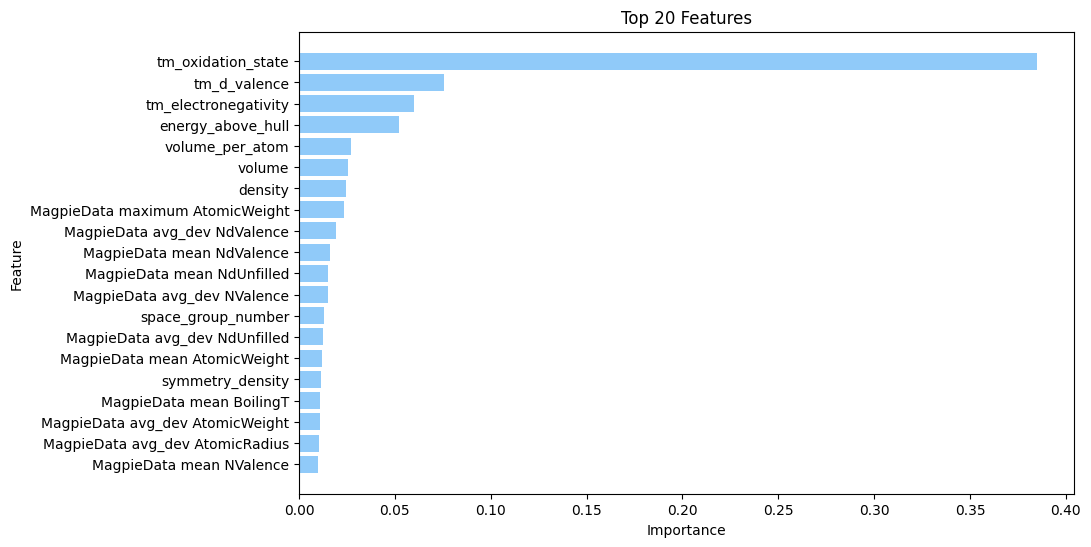

In [ ]:
# Plot feature importance
visualize_feature_importance(bg_rf, bg_Train_df.columns, 20, "#90CAF9")

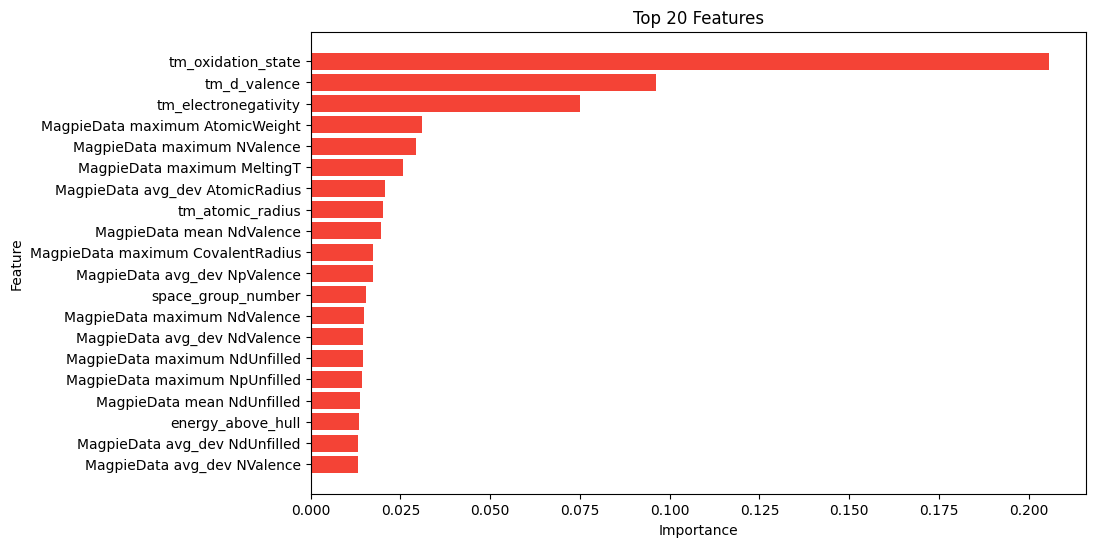

In [ ]:
visualize_feature_importance(bg_xgb, bg_Train_df.columns, 20, "#F44336")

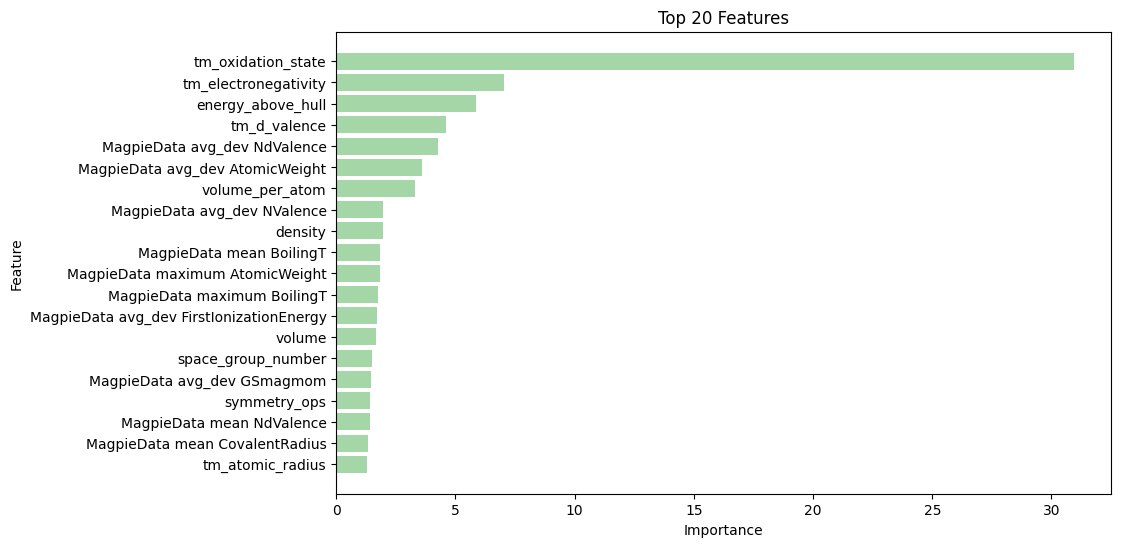

In [ ]:
visualize_feature_importance(bg_cbt, bg_Train_df.columns, 20, "#A5D6A7")

### SHAP Analysis

In [ ]:
# Formation energy
fe_explainer = shap.TreeExplainer(fe_cbt)
fe_shap_values = fe_explainer.shap_values(fe_Test_df)

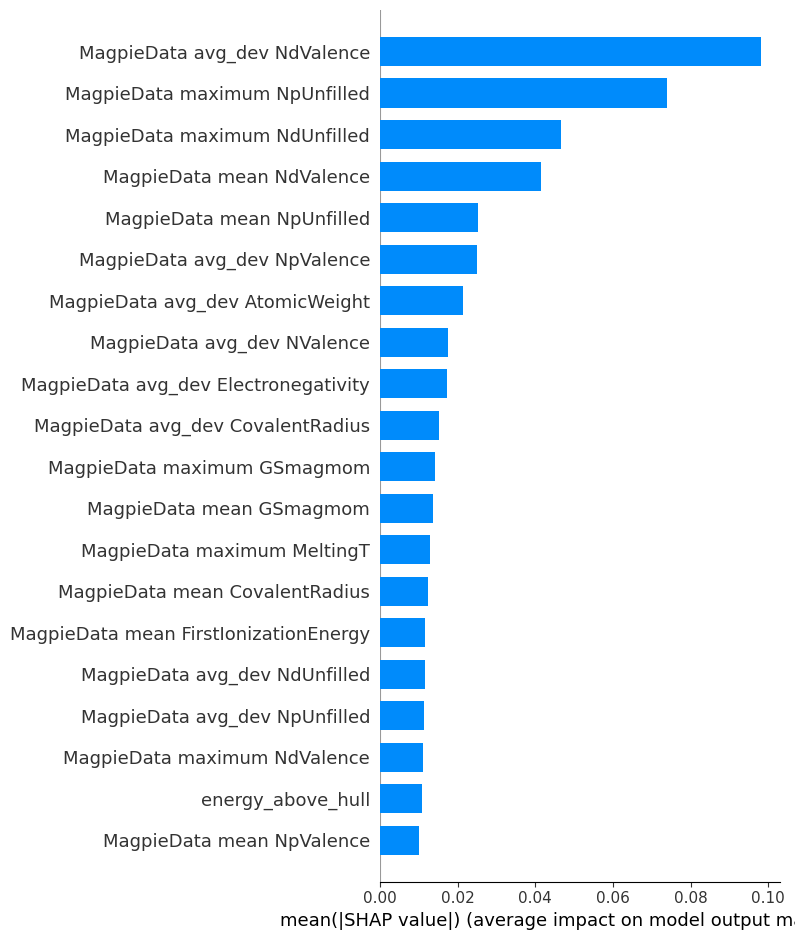

In [ ]:
#Summary Plot
plt.figure(figsize=(10,8))
shap.summary_plot(fe_shap_values, fe_Test_df, plot_type="bar", max_display=20, show=False)
plt.tight_layout()
plt.show()

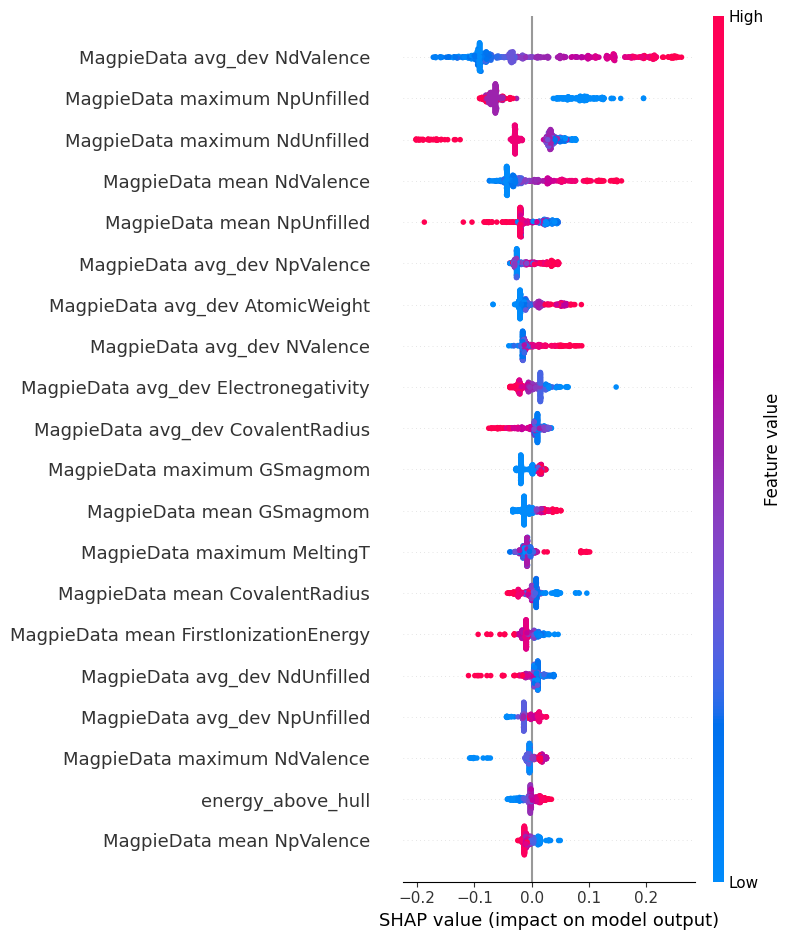

In [ ]:
#Beeswarm Plot
plt.figure(figsize=(10,8))
shap.summary_plot(fe_shap_values, fe_Test_df, plot_type="dot", max_display=20, show=False)
plt.tight_layout()
plt.show()

In [ ]:
# Band gap
bg_explainer = shap.TreeExplainer(bg_cbt)
bg_shap_values = bg_explainer.shap_values(bg_Test_df)

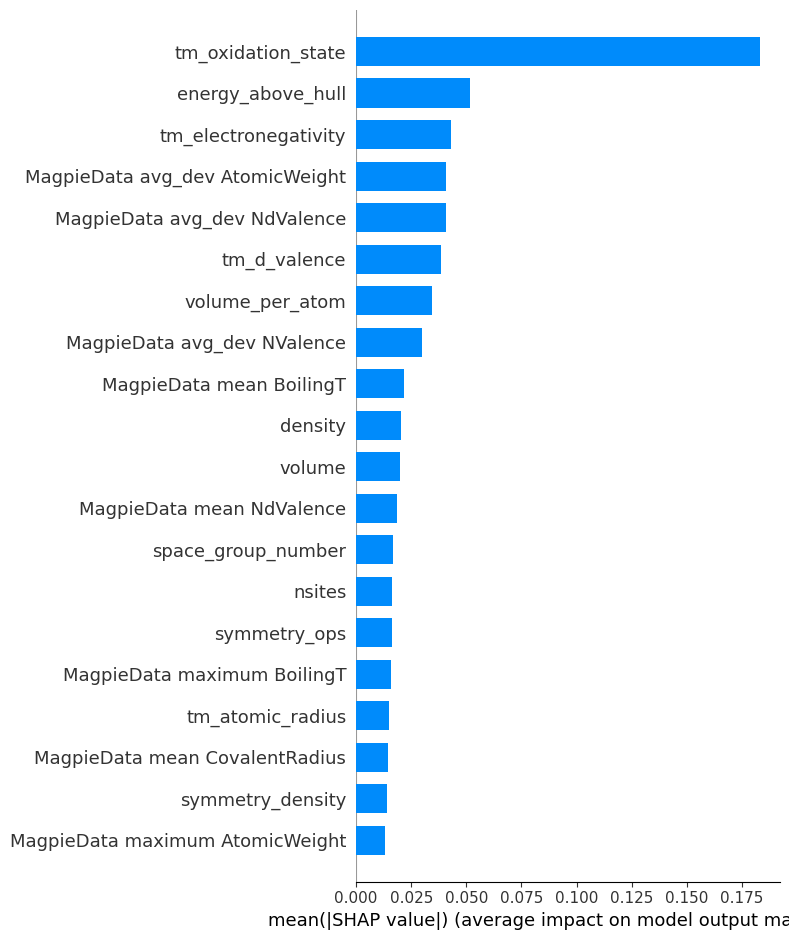

In [ ]:
# summary plot
plt.figure(figsize=(10,8))
shap.summary_plot(bg_shap_values, bg_Test_df, plot_type="bar", max_display=20, show=False)
plt.tight_layout()
plt.show()

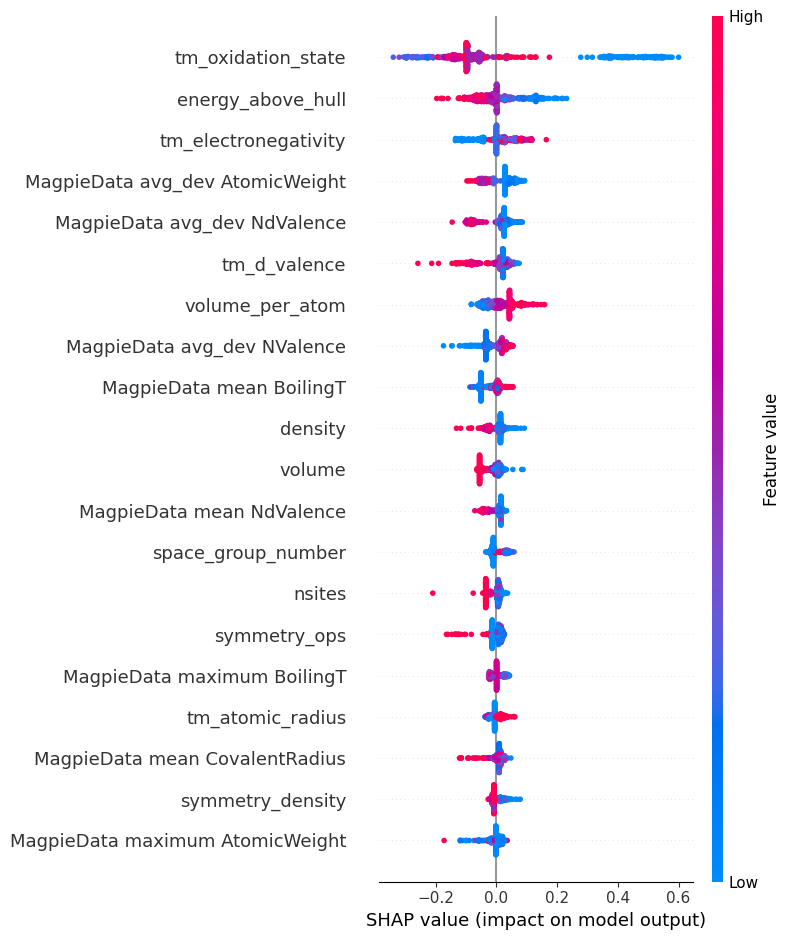

In [ ]:
# beeswarm plot
plt.figure(figsize=(10,8))
shap.summary_plot(bg_shap_values, bg_Test_df, plot_type="dot", max_display=20, show=False)
plt.tight_layout()
plt.show()

### Uncertaintity Quantification


In [ ]:
def fe_train_bootstrap_ensemble(x_train, y_train, n_bootstraps=200):
  models = []
  rng = np.random.RandomState(42)
  n_samples = len(x_train)
  n_boot = int(n_samples * 0.8) #each model should see a slightly different view of the data

  print(f"Training {n_bootstraps} bootstrap models...")

  for i in range(n_bootstraps):
    idx = rng.choice(n_samples, size=n_boot, replace=True)
    x = x_train[idx] if isinstance(x_train, np.ndarray) else x_train.iloc[idx]
    y = y_train[idx] if isinstance(y_train, np.ndarray) else y_train.iloc[idx]

    model = CatBoostRegressor(depth=6, learning_rate=0.06971657856153801, iterations=893, l2_leaf_reg=4.069152717195301,
                           bagging_temperature=0.5623118621923068, border_count=118, random_strength=4.234424969208655,
                           random_seed=i, verbose=0)
    model.fit(x,y)
    models.append(model)
  print("Training bootstrap models complete")
  return models

# Get predictions from trained models
def predict_with_uncertainty(models, x):
  all_preds = np.array([m.predict(x) for m in models])
  mean = np.mean(all_preds, axis=0)
  std = np.std(all_preds, axis=0)
  lower = np.percentile(all_preds, 2.5, axis=0)
  upper = np.percentile(all_preds, 97.5, axis=0)
  return mean, std, lower, upper

def compute_calibration_curve(models, x_test, y_test):
  all_preds = np.array([m.predict(x_test) for m in models])
  confidence_levels = np.linspace(0.05, 0.99, 40)

  empirical_coverages = []

  for conf in confidence_levels:
    alpha = (1 - conf)/2
    lower = np.percentile(all_preds, alpha*100, axis=0)
    upper = np.percentile(all_preds, (1 - alpha)*100, axis=0)
    coverage = np.mean((y_test >= lower) & (y_test <= upper))
    empirical_coverages.append(coverage)

  return confidence_levels, np.array(empirical_coverages)


# Train Bootstrap Models for Formation Energy
fe_models = fe_train_bootstrap_ensemble(fe_Train_df, train_formation_energy, n_bootstraps=200)
fe_mean, fe_std, fe_lower, fe_upper = predict_with_uncertainty(fe_models, fe_Test_df)

Training 200 bootstrap models...
Training bootstrap models complete


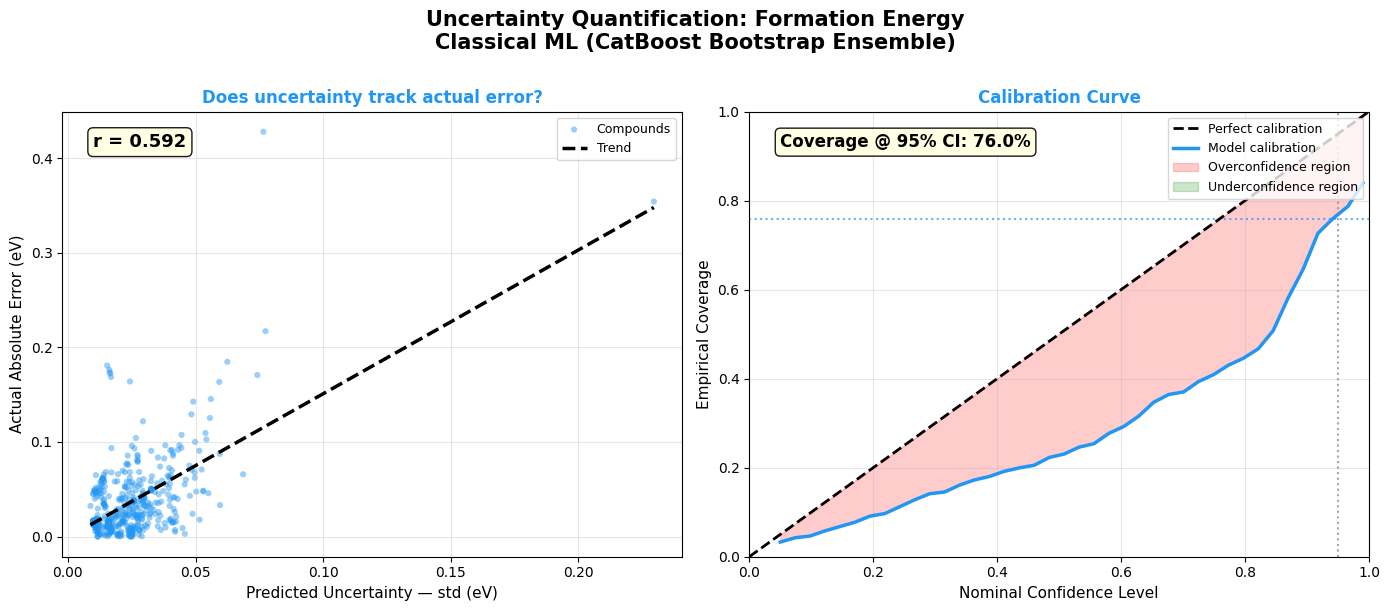

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'Uncertainty Quantification: Formation Energy\n'
    'Classical ML (CatBoost Bootstrap Ensemble)',
    fontsize=15, fontweight='bold', y=1.01
)

y_test_t = np.array(test_formation_energy)
f_mean = fe_mean
f_std = fe_std
f_lower = fe_lower
f_upper = fe_upper
f_models = fe_models
f_color = '#2196F3'  # Blue

# Uncertainty vs Actual Error
ax = axes[0]
actual_error = np.abs(y_test_t - f_mean)

ax.scatter(f_std, actual_error, alpha=0.45, s=20,
           color=f_color, edgecolors='none', label='Compounds')

# Trend line
z = np.polyfit(f_std, actual_error, 1)
x_line = np.linspace(f_std.min(), f_std.max(), 100)
ax.plot(x_line, np.poly1d(z)(x_line), 'black',
        linewidth=2.5, linestyle='--', label='Trend')

# Pearson r
r = np.corrcoef(f_std, actual_error)[0, 1]
ax.text(0.05, 0.92, f'r = {r:.3f}',
        transform=ax.transAxes, fontsize=13, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))

ax.set_xlabel('Predicted Uncertainty — std (eV)', fontsize=11)
ax.set_ylabel('Actual Absolute Error (eV)', fontsize=11)
ax.set_title('Does uncertainty track actual error?',
             fontsize=12, fontweight='bold', color=f_color)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# Calibration Curve
ax = axes[1]
conf_levels, emp_coverages = compute_calibration_curve(f_models, fe_Test_df, y_test_t)

# Perfect calibration diagonal
ax.plot([0, 1], [0, 1], 'k--', linewidth=2,
        label='Perfect calibration', zorder=5)

# Actual calibration curve
ax.plot(conf_levels, emp_coverages, color=f_color,
        linewidth=2.5, label='Model calibration')

# Shade the gap
ax.fill_between(conf_levels, conf_levels, emp_coverages,
                where=(emp_coverages < conf_levels),
                alpha=0.2, color='red', label='Overconfidence region')
ax.fill_between(conf_levels, conf_levels, emp_coverages,
                where=(emp_coverages >= conf_levels),
                alpha=0.2, color='green', label='Underconfidence region')

# Coverage at 95%
idx_95 = np.argmin(np.abs(conf_levels - 0.95))
cov_95 = emp_coverages[idx_95]
ax.axvline(0.95, color='gray', linestyle=':', alpha=0.7)
ax.axhline(cov_95, color=f_color, linestyle=':', alpha=0.7)
ax.text(0.05, 0.92,
        f'Coverage @ 95% CI: {cov_95:.1%}',
        transform=ax.transAxes, fontsize=12, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))

ax.set_xlabel('Nominal Confidence Level', fontsize=11)
ax.set_ylabel('Empirical Coverage', fontsize=11)
ax.set_title('Calibration Curve',
             fontsize=12, fontweight='bold', color=f_color)
ax.legend(fontsize=9, loc='upper right')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)

plt.tight_layout()
#plt.savefig('uq_formation_energy.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
def bg_train_bootstrap_ensemble(x_train, y_train, n_bootstraps=200):
  models = []
  rng = np.random.RandomState(42)
  n_samples = len(x_train)
  n_boot = int(n_samples * 0.8) #each model should see a slightly different view of the data

  print(f"Training {n_bootstraps} bootstrap models...")

  for i in range(n_bootstraps):
    idx = rng.choice(n_samples, size=n_boot, replace=True)
    x = x_train[idx] if isinstance(x_train, np.ndarray) else x_train.iloc[idx]
    y = y_train[idx] if isinstance(y_train, np.ndarray) else y_train.iloc[idx]

    model = CatBoostRegressor(depth=5, learning_rate=0.08802936630210713, iterations=814, l2_leaf_reg=2.966380031216567,
                           bagging_temperature=0.4970498298361245, border_count=246, random_strength=0.09880850964781662,
                           random_seed=i, verbose=0)
    model.fit(x,y)
    models.append(model)
  print("Training bootstrap models complete")
  return models

# Get predictions from trained models
def predict_with_uncertainty(models, x):
  all_preds = np.array([m.predict(x) for m in models])
  mean = np.mean(all_preds, axis=0)
  std = np.std(all_preds, axis=0)
  lower = np.percentile(all_preds, 2.5, axis=0)
  upper = np.percentile(all_preds, 97.5, axis=0)
  return mean, std, lower, upper

def compute_calibration_curve(models, x_test, y_test):
  all_preds = np.array([m.predict(x_test) for m in models])
  confidence_levels = np.linspace(0.05, 0.99, 40)

  empirical_coverages = []

  for conf in confidence_levels:
    alpha = (1 - conf)/2
    lower = np.percentile(all_preds, alpha*100, axis=0)
    upper = np.percentile(all_preds, (1 - alpha)*100, axis=0)
    coverage = np.mean((y_test >= lower) & (y_test <= upper))
    empirical_coverages.append(coverage)

  return confidence_levels, np.array(empirical_coverages)


# Train Bootstrap Models for Band gap
bg_models = bg_train_bootstrap_ensemble(bg_Train_df, Train_bandgap, n_bootstraps=200)
bg_mean, bg_std, bg_lower, bg_upper = predict_with_uncertainty(bg_models, bg_Test_df)

Training 200 bootstrap models...
Training bootstrap models complete


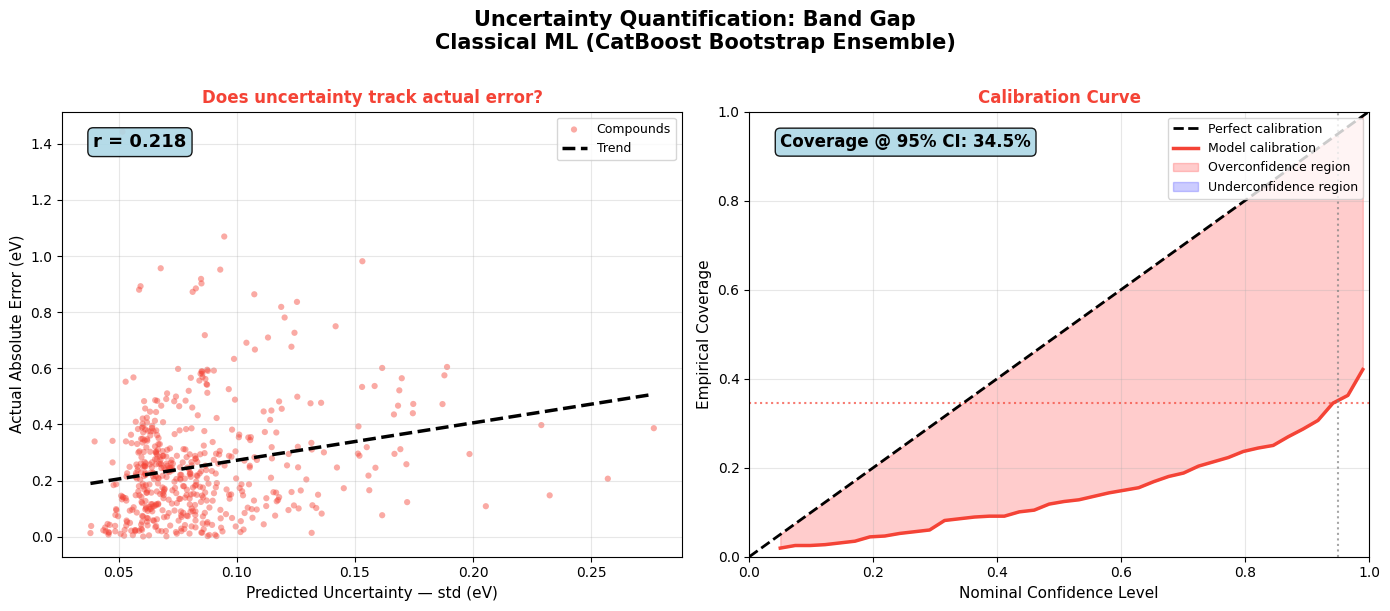

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'Uncertainty Quantification: Band Gap\n'
    'Classical ML (CatBoost Bootstrap Ensemble)',
    fontsize=15, fontweight='bold', y=1.01
)

y_test_bg = np.array(Test_bandgap)
g_mean = bg_mean
g_std = bg_std
g_lower = bg_lower
g_upper = bg_upper
g_models = bg_models
g_color = '#F44336'  # Blue

# Uncertainty vs Actual Error
ax = axes[0]
actual_error = np.abs(y_test_bg - g_mean)

ax.scatter(g_std, actual_error, alpha=0.45, s=20,
           color=g_color, edgecolors='none', label='Compounds')

# Trend line
z = np.polyfit(g_std, actual_error, 1)
x_line = np.linspace(g_std.min(), g_std.max(), 100)
ax.plot(x_line, np.poly1d(z)(x_line), 'black',
        linewidth=2.5, linestyle='--', label='Trend')

# Pearson r
r = np.corrcoef(g_std, actual_error)[0, 1]
ax.text(0.05, 0.92, f'r = {r:.3f}',
        transform=ax.transAxes, fontsize=13, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.9))

ax.set_xlabel('Predicted Uncertainty — std (eV)', fontsize=11)
ax.set_ylabel('Actual Absolute Error (eV)', fontsize=11)
ax.set_title('Does uncertainty track actual error?',
             fontsize=12, fontweight='bold', color=g_color)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# Calibration Curve
ax = axes[1]
conf_levels, emp_coverages = compute_calibration_curve(g_models, bg_Test_df, y_test_bg)

# Perfect calibration diagonal
ax.plot([0, 1], [0, 1], 'k--', linewidth=2,
        label='Perfect calibration', zorder=5)

# Actual calibration curve
ax.plot(conf_levels, emp_coverages, color=g_color,
        linewidth=2.5, label='Model calibration')

# Shade the gap
ax.fill_between(conf_levels, conf_levels, emp_coverages,
                where=(emp_coverages < conf_levels),
                alpha=0.2, color='red', label='Overconfidence region')
ax.fill_between(conf_levels, conf_levels, emp_coverages,
                where=(emp_coverages >= conf_levels),
                alpha=0.2, color='blue', label='Underconfidence region')

# Coverage at 95%
idx_95 = np.argmin(np.abs(conf_levels - 0.95))
cov_95 = emp_coverages[idx_95]
ax.axvline(0.95, color='gray', linestyle=':', alpha=0.7)
ax.axhline(cov_95, color=g_color, linestyle=':', alpha=0.7)
ax.text(0.05, 0.92,
        f'Coverage @ 95% CI: {cov_95:.1%}',
        transform=ax.transAxes, fontsize=12, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.9))

ax.set_xlabel('Nominal Confidence Level', fontsize=11)
ax.set_ylabel('Empirical Coverage', fontsize=11)
ax.set_title('Calibration Curve',
             fontsize=12, fontweight='bold', color=g_color)
ax.legend(fontsize=9, loc='upper right')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)

plt.tight_layout()
#plt.savefig('uq_formation_energy.png', dpi=300, bbox_inches='tight')
plt.show()